# RetailPulse — Demand Forecasting

This notebook develops the demand forecasting component of RetailPulse.

Models:
- Prophet
- LSTM
- Hybrid Prophet + LSTM

The forecasting dataset is derived from the cleaned sales dataset:
`clean_sales.parquet`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
sales_df = pd.read_parquet("../data/processed/clean_sales.parquet")

print("Dataset loaded successfully.")
print("Shape:", sales_df.shape)

Dataset loaded successfully.
Shape: (1007913, 11)


In [3]:
sales_df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,STRAWBERRY CERAMIC TRINKET BOX


In [ ]:
sales_df.info()

In [ ]:
sales_df.describe()

In [4]:
missing_report = pd.DataFrame({
    "missing_count": sales_df.isna().sum(),
    "missing_percentage": (
        sales_df.isna().mean() * 100
    ).round(2)
})

missing_report.sort_values("missing_percentage",ascending=False)

,missing_count,missing_percentage
customer_id,228488,22.67
invoice,0,0.00
stock_code,0,0.00
description,0,0.00
quantity,0,0.00
invoice_date,0,0.00
unit_price,0,0.00
country,0,0.00
is_cancelled,0,0.00
revenue,0,0.00


In [5]:
print("Duplicate rows:", sales_df.duplicated().sum())

Duplicate rows: 0


In [6]:
print("Minimum date:", sales_df["invoice_date"].min())
print("Maximum date:", sales_df["invoice_date"].max())

Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00


In [7]:
print("Negative quantity:", (sales_df["quantity"] < 0).sum())
print("Zero quantity:", (sales_df["quantity"] == 0).sum())
print("Negative revenue:", (sales_df["revenue"] < 0).sum())
print("Zero revenue:", (sales_df["revenue"] == 0).sum())

Negative quantity: 0
Zero quantity: 0
Negative revenue: 0
Zero revenue: 0


In [ ]:
print("Unique products:", sales_df["stock_code"].nunique())
print("Unique products with descriptions:",sales_df["description"].nunique())

In [8]:
sales_df["stock_code"].value_counts().head(20)

stock_code
85123A    5511
85099B    4042
22423     3950
21212     3181
20725     3090
84879     2848
47566     2705
21232     2478
22383     2436
20727     2402
22197     2366
21931     2352
22386     2269
22411     2209
22469     2195
84991     2179
22382     2173
21080     2156
22384     2137
22139     2103
Name: count, dtype: int64[pyarrow]

In [9]:
daily_demand = (sales_df.groupby(sales_df["invoice_date"].dt.date)["quantity"].sum().reset_index())

daily_demand.columns = ["date", "demand"]

daily_demand["date"] = pd.to_datetime(daily_demand["date"])

daily_demand.head()

,date,demand
0,2009-12-01,26098
1,2009-12-02,31804
2,2009-12-03,49221
3,2009-12-04,21210
4,2009-12-05,5119


In [22]:
daily_demand.shape

(604, 3)

In [ ]:
daily_demand.describe()

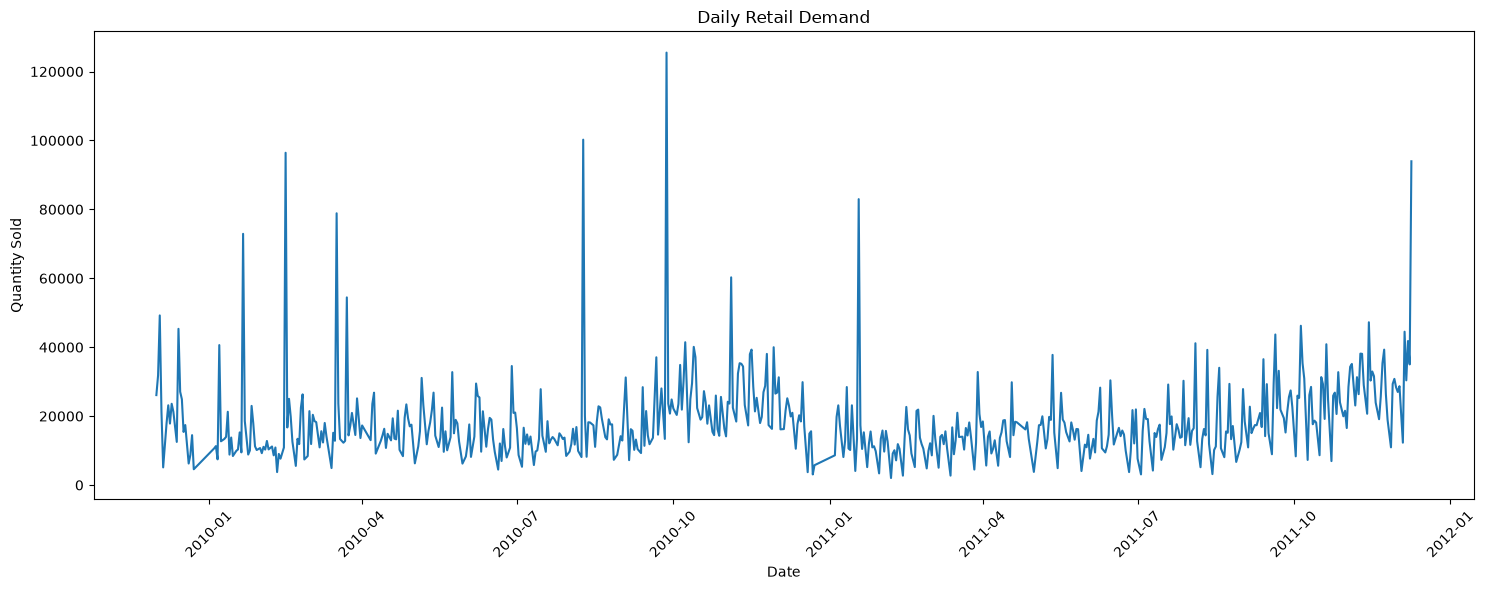

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(daily_demand["date"],daily_demand["demand"])

plt.title("Daily Retail Demand")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [13]:
monthly_demand = (
    daily_demand
    .set_index("date")
    .resample("ME")["demand"]
    .sum()
    .reset_index()
)

monthly_demand.head()

,date,demand
0,2009-12-31,425461
1,2010-01-31,390672
2,2010-02-28,381879
3,2010-03-31,526026
4,2010-04-30,366705


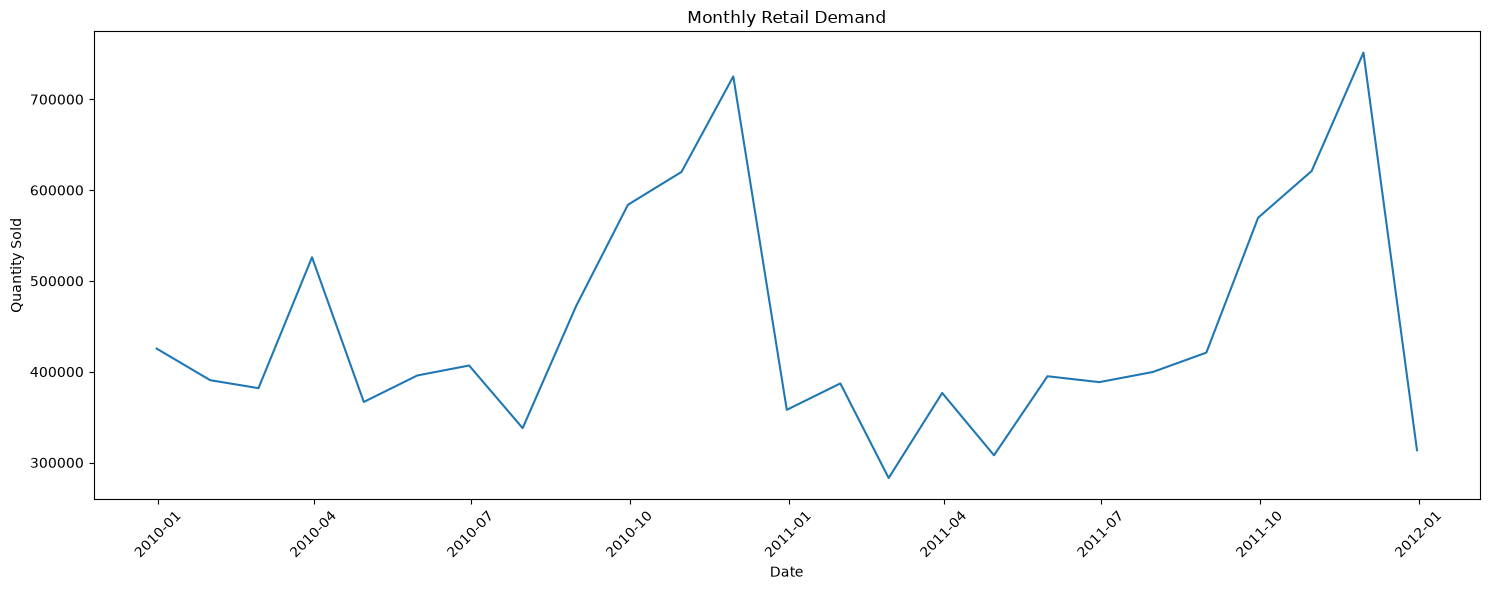

In [14]:
plt.figure(figsize=(15, 6))

plt.plot(monthly_demand["date"],monthly_demand["demand"])

plt.title("Monthly Retail Demand")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [15]:
# Make sure daily_demand is sorted

daily_demand = daily_demand.sort_values("date").reset_index(drop=True)

# Complete calendar range
full_date_range = pd.date_range(
    start=daily_demand["date"].min(),
    end=daily_demand["date"].max(),
    freq="D"
)

print("Observed dates:", len(daily_demand))
print("Expected calendar dates:", len(full_date_range))
print("Missing calendar dates:",len(full_date_range) - len(daily_demand))

Observed dates: 604
Expected calendar dates: 739
Missing calendar dates: 135


In [16]:
missing_dates = full_date_range.difference(daily_demand["date"])

print("Number of missing dates:", len(missing_dates))
print("\nFirst 20 missing dates:")
print(missing_dates[:20])

Number of missing dates: 135

First 20 missing dates:
DatetimeIndex(['2009-12-12', '2009-12-19', '2009-12-24', '2009-12-25',
               '2009-12-26', '2009-12-27', '2009-12-28', '2009-12-29',
               '2009-12-30', '2009-12-31', '2010-01-01', '2010-01-02',
               '2010-01-03', '2010-01-09', '2010-01-16', '2010-01-23',
               '2010-01-30', '2010-02-06', '2010-02-13', '2010-02-20'],
              dtype='datetime64[s]', freq=None)


In [17]:
daily_demand["day_of_week"] = daily_demand["date"].dt.day_name()

weekday_summary = (daily_demand.groupby("day_of_week")["demand"].agg(["count", "mean", "median", "sum"]))

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_summary = weekday_summary.reindex(weekday_order)

weekday_summary

,count,mean,median,sum
day_of_week,,,,
Monday,94,21604.712766,15866.0,2030843
Tuesday,104,20605.384615,17430.5,2142960
Wednesday,104,19228.519231,17756.5,1999766
Thursday,103,22528.310680,18858.0,2320416
Friday,99,16956.838384,14865.0,1678727
Saturday,1,5119.000000,5119.0,5119
Sunday,99,10376.939394,10537.0,1027317


In [18]:
print("Dates available by weekday:")
print(daily_demand["day_of_week"].value_counts().reindex(weekday_order))

Dates available by weekday:
day_of_week
Monday        94
Tuesday      104
Wednesday    104
Thursday     103
Friday        99
Saturday       1
Sunday        99
Name: count, dtype: int64


In [123]:
forecast_df = daily_demand[["date", "demand"]].copy()

forecast_df = forecast_df.rename(
    columns={
        "date": "ds",
        "demand": "y"
    }
)

forecast_df = forecast_df.sort_values("ds").reset_index(drop=True)

forecast_df.head()

,ds,y
0,2009-12-01,26098
1,2009-12-02,31804
2,2009-12-03,49221
3,2009-12-04,21210
4,2009-12-05,5119


In [ ]:
forecast_df.shape

In [ ]:
print(forecast_df.isna().sum())
print("duplicated dates",forecast_df["ds"].duplicated().sum())

In [ ]:
q1 = forecast_df["y"].quantile(0.25)
q3 = forecast_df["y"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = forecast_df[
    (forecast_df["y"] < lower_bound) |
    (forecast_df["y"] > upper_bound)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))

In [ ]:
outliers.sort_values("y", ascending=False).head(20)

In [124]:
forecast_df["rolling_7d"] = (forecast_df["y"].rolling(window=7).mean())

forecast_df["rolling_30d"] = (forecast_df["y"].rolling(window=30).mean())

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecast_df["ds"],
    forecast_df["y"],
    alpha=0.35,
    label="Daily Demand"
)

plt.plot(
    forecast_df["ds"],
    forecast_df["rolling_7d"],
    label="7-Day Rolling Mean"
)

plt.plot(
    forecast_df["ds"],
    forecast_df["rolling_30d"],
    label="30-Day Rolling Mean"
)

plt.title("Retail Demand with Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [125]:
daily_complete = (daily_demand.set_index("date").reindex(full_date_range))

daily_complete.index.name = "date"

daily_complete = daily_complete.reset_index()

daily_complete.head(15)

,date,demand,day_of_week
0,2009-12-01,26098.0,Tuesday
1,2009-12-02,31804.0,Wednesday
2,2009-12-03,49221.0,Thursday
3,2009-12-04,21210.0,Friday
4,2009-12-05,5119.0,Saturday
5,2009-12-06,11533.0,Sunday
6,2009-12-07,17955.0,Monday
7,2009-12-08,23143.0,Tuesday
8,2009-12-09,17840.0,Wednesday
9,2009-12-10,23579.0,Thursday


In [126]:
daily_complete["demand"] = (daily_complete["demand"].fillna(0))

In [127]:
daily_complete["day_of_week"] = (daily_complete["date"].dt.day_name())

zero_demand_by_day = (daily_complete[daily_complete["demand"] == 0].groupby("day_of_week").size().reindex(weekday_order))

zero_demand_by_day

day_of_week
Monday        11
Tuesday        2
Wednesday      2
Thursday       3
Friday         7
Saturday     104
Sunday         6
dtype: int64

In [128]:
daily_complete[daily_complete["demand"] == 0].head(30)

,date,demand,day_of_week
11,2009-12-12,0.0,Saturday
18,2009-12-19,0.0,Saturday
23,2009-12-24,0.0,Thursday
24,2009-12-25,0.0,Friday
25,2009-12-26,0.0,Saturday
26,2009-12-27,0.0,Sunday
27,2009-12-28,0.0,Monday
28,2009-12-29,0.0,Tuesday
29,2009-12-30,0.0,Wednesday
30,2009-12-31,0.0,Thursday


In [129]:
non_saturday_zeros = daily_complete[
    (daily_complete["demand"] == 0) &
    (daily_complete["day_of_week"] != "Saturday")
]

print("Non-Saturday zero-demand dates:",len(non_saturday_zeros))

non_saturday_zeros.head(30)

Non-Saturday zero-demand dates: 31


,date,demand,day_of_week
23,2009-12-24,0.0,Thursday
24,2009-12-25,0.0,Friday
26,2009-12-27,0.0,Sunday
27,2009-12-28,0.0,Monday
28,2009-12-29,0.0,Tuesday
29,2009-12-30,0.0,Wednesday
30,2009-12-31,0.0,Thursday
31,2010-01-01,0.0,Friday
33,2010-01-03,0.0,Sunday
122,2010-04-02,0.0,Friday


In [130]:
forecast_df = daily_complete[
    ["date", "demand"]
].copy()

forecast_df = forecast_df.rename(
    columns={
        "date": "ds",
        "demand": "y"
    }
)

forecast_df = forecast_df.sort_values(
    "ds"
).reset_index(drop=True)

forecast_df.head()

,ds,y
0,2009-12-01,26098.0
1,2009-12-02,31804.0
2,2009-12-03,49221.0
3,2009-12-04,21210.0
4,2009-12-05,5119.0


In [131]:
print("Shape:", forecast_df.shape)

print("Date range:",forecast_df["ds"].min(),"→",forecast_df["ds"].max())

print(
    "Missing values:\n",
    forecast_df.isna().sum()
)

print("Duplicate dates:",forecast_df["ds"].duplicated().sum())

print("Zero-demand days:",(forecast_df["y"] == 0).sum())

Shape: (739, 2)
Date range: 2009-12-01 00:00:00 → 2011-12-09 00:00:00
Missing values:
 ds    0
y     0
dtype: int64
Duplicate dates: 0
Zero-demand days: 135


In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecast_df["ds"],
    forecast_df["y"],
    alpha=0.6
)

plt.title("Complete Daily Retail Demand")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [132]:
forecast_df["rolling_7d"] = (forecast_df["y"].rolling(window=7).mean())

forecast_df["rolling_30d"] = (forecast_df["y"].rolling(window=30).mean())

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecast_df["ds"],
    forecast_df["y"],
    alpha=0.25,
    label="Daily Demand"
)

plt.plot(
    forecast_df["ds"],
    forecast_df["rolling_7d"],
    label="7-Day Rolling Mean"
)

plt.plot(
    forecast_df["ds"],
    forecast_df["rolling_30d"],
    label="30-Day Rolling Mean"
)

plt.title("Complete Retail Demand with Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [133]:
forecast_df = forecast_df[["ds", "y"]].copy()

In [134]:
split_index = int(len(forecast_df) * 0.80)

train_df = forecast_df.iloc[:split_index].copy()

test_df = forecast_df.iloc[split_index:].copy()

In [ ]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining period:")
print(train_df["ds"].min(),"→",train_df["ds"].max())

print("\nTesting period:")
print(test_df["ds"].min(),"→",test_df["ds"].max())

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    train_df["ds"],
    train_df["y"],
    label="Training"
)

plt.plot(
    test_df["ds"],
    test_df["y"],
    label="Testing"
)

plt.axvline(
    test_df["ds"].min(),
    linestyle="--",
    label="Train/Test Split"
)

plt.title("Retail Demand — Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
forecast_path = processed_dir / "daily_demand.parquet"

forecast_df.to_parquet(
    forecast_path,
    engine="pyarrow",
    index=False
)

print("Saved:", forecast_path.resolve())

## Forecasting Configuration

The forecasting experiment uses a chronological development/test split.

- Total observations: 739 days
- Development set: 591 days
- Final test set: 148 days
- Cross-validation: expanding-window time-series CV
- Initial training window: 365 days
- Validation horizon: 56 days
- CV step: 56 days

The final test set remains untouched until model selection is complete.

In [ ]:
CV_INITIAL_DAYS = 365
CV_HORIZON_DAYS = 56
CV_PERIOD_DAYS = 56

FINAL_TEST_SIZE = 148

print("CV configuration")
print("-" * 40)
print("Initial training window:", CV_INITIAL_DAYS)
print("Validation horizon:", CV_HORIZON_DAYS)
print("CV step:", CV_PERIOD_DAYS)
print("Final test observations:", FINAL_TEST_SIZE)

In [ ]:
development_df = forecast_df.iloc[:591].copy()
final_test_df = forecast_df.iloc[591:].copy()

cv_folds = []

initial_train = CV_INITIAL_DAYS
horizon = CV_HORIZON_DAYS
period = CV_PERIOD_DAYS

fold = 1
train_end = initial_train

while train_end + horizon <= len(development_df):

    train_start_idx = 0
    train_end_idx = train_end

    validation_start_idx = train_end
    validation_end_idx = train_end + horizon

    cv_folds.append({
        "fold": fold,
        "train_start": development_df.iloc[train_start_idx]["ds"],
        "train_end": development_df.iloc[train_end_idx - 1]["ds"],
        "validation_start": development_df.iloc[validation_start_idx]["ds"],
        "validation_end": development_df.iloc[validation_end_idx - 1]["ds"],
        "train_size": train_end_idx,
        "validation_size": horizon
    })

    fold += 1
    train_end += period

cv_folds_df = pd.DataFrame(cv_folds)

cv_folds_df

In [ ]:
print("Final test:",final_test_df["ds"].min(),"→",final_test_df["ds"].max())

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

for _, row in cv_folds_df.iterrows():

    fold = int(row["fold"])

    train_start = row["train_start"]
    train_end = row["train_end"]

    val_start = row["validation_start"]
    val_end = row["validation_end"]

    plt.plot(
        [train_start, train_end],
        [fold, fold],
        linewidth=8,
        label="Training" if fold == 1 else ""
    )

    plt.plot(
        [val_start, val_end],
        [fold, fold],
        linewidth=8,
        label="Validation" if fold == 1 else ""
    )

plt.yticks(
    range(1, len(cv_folds_df) + 1),
    [f"Fold {i}" for i in range(1, len(cv_folds_df) + 1)]
)

plt.xlabel("Date")
plt.ylabel("CV Fold")
plt.title("RetailPulse — Expanding Window Time-Series Cross-Validation")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
try:
    from prophet import Prophet
    from prophet.diagnostics import cross_validation, performance_metrics

    print("Prophet imported successfully.")
except ImportError as e:
    print("Prophet is not installed.")
    print(e)

In [ ]:
prophet_dev = development_df[["ds", "y"]].copy()
prophet_test = final_test_df[["ds", "y"]].copy()

print("Development:", prophet_dev.shape)
print("Final test:", prophet_test.shape)

prophet_dev.head()

In [ ]:
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

In [ ]:
prophet_model.fit(prophet_dev)

In [ ]:
future_test = prophet_model.make_future_dataframe(
    periods=len(prophet_test),
    freq="D",
    include_history=False
)

prophet_test_forecast = prophet_model.predict(future_test)

In [ ]:
prophet_test_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head(10)

In [ ]:
cv_cutoffs = [
    pd.Timestamp(row["validation_start"]) - pd.Timedelta(days=1)
    for _, row in cv_folds_df.iterrows()
]



In [ ]:
prophet_cv = cross_validation(
    prophet_model,
    cutoffs=cv_cutoffs,
    horizon="56 days"
)

In [ ]:

print("CV shape:", prophet_cv.shape)

prophet_cv.head()

In [ ]:
prophet_cv.groupby("cutoff").agg(
    validation_start=("ds", "min"),
    validation_end=("ds", "max"),
    observations=("ds", "count")
)

In [ ]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    error = actual - predicted

    mae = np.mean(np.abs(error))

    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE only where actual demand > 0
    non_zero = actual != 0

    if non_zero.sum() > 0:
        mape = np.mean(
            np.abs((actual[non_zero] - predicted[non_zero])/ actual[non_zero])) * 100
    else:
        mape = np.nan

    # WAPE
    denominator = np.sum(np.abs(actual))

    if denominator != 0:
        wape = (np.sum(np.abs(error))/ denominator) * 100
    else:
        wape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "WAPE": wape
    }

In [ ]:
prophet_fold_results = []

for cutoff, fold_data in prophet_cv.groupby("cutoff"):

    metrics = calculate_metrics(
        fold_data["y"],
        fold_data["yhat"]
    )

    metrics["cutoff"] = cutoff

    prophet_fold_results.append(metrics)

prophet_fold_results = pd.DataFrame(
    prophet_fold_results
)

prophet_fold_results

In [ ]:
prophet_cv_summary = pd.DataFrame({
    "Model": ["Prophet"],
    "MAE_mean": [prophet_fold_results["MAE"].mean()],
    "MAE_std": [prophet_fold_results["MAE"].std()],
    "RMSE_mean": [prophet_fold_results["RMSE"].mean()],
    "RMSE_std": [prophet_fold_results["RMSE"].std()],
    "MAPE_mean": [prophet_fold_results["MAPE"].mean()],
    "MAPE_std": [prophet_fold_results["MAPE"].std()],
    "WAPE_mean": [prophet_fold_results["WAPE"].mean()],
    "WAPE_std": [prophet_fold_results["WAPE"].std()]
})

prophet_cv_summary

In [ ]:
plt.figure(figsize=(16, 7))

plt.plot(
    prophet_cv["ds"],
    prophet_cv["y"],
    label="Actual",
    alpha=0.7
)

plt.plot(
    prophet_cv["ds"],
    prophet_cv["yhat"],
    label="Prophet Forecast",
    alpha=0.8
)

plt.title("Prophet — Cross-Validation Predictions")

plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
for cutoff, fold_data in prophet_cv.groupby("cutoff"):
    
    plt.figure(figsize=(14, 5))

    plt.plot(
        fold_data["ds"],
        fold_data["y"],
        label="Actual"
    )

    plt.plot(
        fold_data["ds"],
        fold_data["yhat"],
        label="Prophet"
    )

    plt.title(f"Prophet CV — Cutoff: {cutoff.date()}")

    plt.xlabel("Date")
    plt.ylabel("Demand")
    plt.legend()
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [ ]:
def evaluate_prophet_model(
    model,
    train_df,
    cv_cutoffs,
    horizon_days=56
):
    """
    Train Prophet and evaluate using predefined
    time-series CV cutoffs.
    """

    # Train
    model.fit(train_df)

    # Cross-validation
    cv_results = cross_validation(
        model,
        cutoffs=cv_cutoffs,
        horizon=f"{horizon_days} days"
    )

    # Prevent physically impossible negative demand
    cv_results["yhat_clipped"] = (
        cv_results["yhat"].clip(lower=0)
    )

    fold_results = []

    for cutoff, fold_data in cv_results.groupby("cutoff"):

        metrics = calculate_metrics(
            fold_data["y"].values,
            fold_data["yhat_clipped"].values
        )

        metrics["cutoff"] = cutoff

        fold_results.append(metrics)

    fold_results = pd.DataFrame(fold_results)

    summary = {
        "MAE_mean": fold_results["MAE"].mean(),
        "MAE_std": fold_results["MAE"].std(),

        "RMSE_mean": fold_results["RMSE"].mean(),
        "RMSE_std": fold_results["RMSE"].std(),

        "MAPE_mean": fold_results["MAPE"].mean(),
        "MAPE_std": fold_results["MAPE"].std(),

        "WAPE_mean": fold_results["WAPE"].mean(),
        "WAPE_std": fold_results["WAPE"].std()
    }

    return cv_results, fold_results, summary

In [ ]:
baseline_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

baseline_cv, baseline_folds, baseline_summary = (
    evaluate_prophet_model(
        baseline_model,
        prophet_dev,
        cv_cutoffs,
        horizon_days=56
    )
)

In [ ]:
pd.DataFrame([baseline_summary])

In [ ]:
prophet_configs = {
    "Prophet_Default": {
        "changepoint_prior_scale": 0.05,
        "seasonality_mode": "additive"
    },

    "Prophet_Flexible": {
        "changepoint_prior_scale": 0.10,
        "seasonality_mode": "additive"
    },

    "Prophet_Smooth": {
        "changepoint_prior_scale": 0.01,
        "seasonality_mode": "additive"
    }
}

In [ ]:
prophet_comparison = []

prophet_cv_results = {}

for model_name, params in prophet_configs.items():

    print(f"Evaluating {model_name}...")

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=params[
            "changepoint_prior_scale"
        ],
        seasonality_mode=params[
            "seasonality_mode"
        ]
    )

    cv_results, fold_results, summary = (
        evaluate_prophet_model(
            model,
            prophet_dev,
            cv_cutoffs,
            horizon_days=56
        )
    )

    prophet_cv_results[model_name] = {
        "cv": cv_results,
        "folds": fold_results
    }

    prophet_comparison.append({"Model": model_name,**summary})

prophet_comparison_df = pd.DataFrame(prophet_comparison)

prophet_comparison_df

In [ ]:
prophet_comparison_df.sort_values("WAPE_mean")

In [ ]:
best_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.01,
    seasonality_mode="additive"
)

best_prophet.fit(prophet_dev)

In [ ]:
prophet_dev_forecast = best_prophet.predict(prophet_dev[["ds"]])

In [ ]:
prophet_dev_predictions = prophet_dev_forecast[["ds", "yhat"]].copy()

prophet_dev_predictions["yhat"] = (prophet_dev_predictions["yhat"].clip(lower=0))

In [ ]:
residual_df = prophet_dev.merge(prophet_dev_predictions,on="ds",how="left")

In [ ]:
residual_df["residual"] = (residual_df["y"] -residual_df["yhat"])
residual_df.head()

In [ ]:
residual_df["residual"].describe()

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(residual_df["ds"],residual_df["residual"])

plt.axhline(0,linestyle="--")

plt.title("Prophet Residuals — Development Period")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(14, 5))

plot_acf(residual_df["residual"],lags=60,zero=False)

plt.title("Prophet Residual Autocorrelation")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(residual_df["residual"],bins=50)

plt.axvline(0,linestyle="--")

plt.title("Distribution of Prophet Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

In [ ]:
import site

print(site.getsitepackages())

In [ ]:
!python --version
!python -m pip show tensorflow

In [1]:
import sys
import tensorflow as tf

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nTensorFlow version:")
print(tf.__version__)

print("\nCPU:")
print(tf.config.list_physical_devices("CPU"))

Python executable:
e:\RetailPulse\.venv311\Scripts\python.exe

Python version:
3.11.2 (tags/v3.11.2:878ead1, Feb  7 2023, 16:38:35) [MSC v.1934 64 bit (AMD64)]

TensorFlow version:
2.17.1

CPU:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


#LSTM Demand Forecasting

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("Num GPUs:", len(tf.config.list_physical_devices("GPU")))
print("CPU:", tf.config.list_physical_devices("CPU"))

TensorFlow: 2.17.1
Num GPUs: 0
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [21]:
lstm_df = daily_demand.copy()

lstm_df["date"] = pd.to_datetime(lstm_df["date"])

lstm_df = (
    lstm_df
    .sort_values("date")
    .reset_index(drop=True)
)

# Rename for consistency with Prophet
lstm_df = lstm_df.rename(
    columns={
        "date": "ds",
        "demand": "y"
    }
)

lstm_df = lstm_df[["ds", "y"]]

print("Shape:", lstm_df.shape)

print("\nColumns:")
print(lstm_df.columns.tolist())

print("\nDate range:")
print(lstm_df["ds"].min(), "→", lstm_df["ds"].max())

print("\nMissing values:")
print(lstm_df.isna().sum())

print("\nDuplicate dates:")
print(lstm_df["ds"].duplicated().sum())

lstm_df.head()

Shape: (604, 2)

Columns:
['ds', 'y']

Date range:
2009-12-01 00:00:00 → 2011-12-09 00:00:00

Missing values:
ds    0
y     0
dtype: int64

Duplicate dates:
0


,ds,y
0,2009-12-01,26098
1,2009-12-02,31804
2,2009-12-03,49221
3,2009-12-04,21210
4,2009-12-05,5119


In [23]:
# Make sure dates are datetime
lstm_df["ds"] = pd.to_datetime(lstm_df["ds"])

# Create complete daily calendar
full_dates = pd.date_range(
    start=lstm_df["ds"].min(),
    end=lstm_df["ds"].max(),
    freq="D"
)

print("Expected calendar dates:", len(full_dates))

Expected calendar dates: 739


In [24]:
# Reindex to complete daily calendar
lstm_df_full = (
    lstm_df
    .set_index("ds")
    .reindex(full_dates)
    .rename_axis("ds")
    .reset_index()
)

print("Shape before filling missing demand:")
print(lstm_df_full.shape)

print("\nMissing values:")
print(lstm_df_full.isna().sum())

Shape before filling missing demand:
(739, 2)

Missing values:
ds      0
y     135
dtype: int64


In [25]:
lstm_df_full["y"] = lstm_df_full["y"].fillna(0)

In [26]:
print("Shape:", lstm_df_full.shape)

print("\nMissing values:")
print(lstm_df_full.isna().sum())

print("\nDate range:")
print(
    lstm_df_full["ds"].min(),
    "→",
    lstm_df_full["ds"].max()
)

print("\nDuplicate dates:")
print(lstm_df_full["ds"].duplicated().sum())

lstm_df_full.head()

Shape: (739, 2)

Missing values:
ds    0
y     0
dtype: int64

Date range:
2009-12-01 00:00:00 → 2011-12-09 00:00:00

Duplicate dates:
0


,ds,y
0,2009-12-01,26098.0
1,2009-12-02,31804.0
2,2009-12-03,49221.0
3,2009-12-04,21210.0
4,2009-12-05,5119.0


In [27]:
zero_days = (lstm_df_full["y"] == 0).sum()

print("Total zero-demand days:", zero_days)

Total zero-demand days: 135


In [ ]:
print(lstm_df_full[lstm_df_full["y"] == 0].head(20))

           ds    y
11 2009-12-12  0.0
18 2009-12-19  0.0
23 2009-12-24  0.0
24 2009-12-25  0.0
25 2009-12-26  0.0
26 2009-12-27  0.0
27 2009-12-28  0.0
28 2009-12-29  0.0
29 2009-12-30  0.0
30 2009-12-31  0.0
31 2010-01-01  0.0
32 2010-01-02  0.0
33 2010-01-03  0.0
39 2010-01-09  0.0
46 2010-01-16  0.0
53 2010-01-23  0.0
60 2010-01-30  0.0
67 2010-02-06  0.0
74 2010-02-13  0.0
81 2010-02-20  0.0


In [29]:
FINAL_TEST = pd.Timestamp("2011-07-15")

lstm_train = lstm_df_full[lstm_df_full["ds"] < FINAL_TEST].copy()

lstm_test = lstm_df_full[lstm_df_full["ds"] >= FINAL_TEST].copy()

print("Training shape:", lstm_train.shape)
print("Testing shape:", lstm_test.shape)

print("\nTraining period:")
print(lstm_train["ds"].min(),"→",lstm_train["ds"].max())

print("\nTesting period:")
print(lstm_test["ds"].min(),"→",lstm_test["ds"].max())

Training shape: (591, 2)
Testing shape: (148, 2)

Training period:
2009-12-01 00:00:00 → 2011-07-14 00:00:00

Testing period:
2011-07-15 00:00:00 → 2011-12-09 00:00:00


In [31]:
LOOKBACK = 30

cv_folds = [
    {
        "fold": 1,
        "train_start": "2009-12-01",
        "train_end": "2010-11-30",
        "validation_start": "2010-12-01",
        "validation_end": "2011-01-25"
    },
    {
        "fold": 2,
        "train_start": "2009-12-01",
        "train_end": "2011-01-25",
        "validation_start": "2011-01-26",
        "validation_end": "2011-03-22"
    },
    {
        "fold": 3,
        "train_start": "2009-12-01",
        "train_end": "2011-03-22",
        "validation_start": "2011-03-23",
        "validation_end": "2011-05-17"
    },
    {
        "fold": 4,
        "train_start": "2009-12-01",
        "train_end": "2011-05-17",
        "validation_start": "2011-05-18",
        "validation_end": "2011-07-12"
    }
]

cv_folds_df = pd.DataFrame(cv_folds)

cv_folds_df

,fold,train_start,train_end,validation_start,validation_end
0,1,2009-12-01,2010-11-30,2010-12-01,2011-01-25
1,2,2009-12-01,2011-01-25,2011-01-26,2011-03-22
2,3,2009-12-01,2011-03-22,2011-03-23,2011-05-17
3,4,2009-12-01,2011-05-17,2011-05-18,2011-07-12


In [32]:
def create_lstm_sequences(data, lookback):
    """
    Create sequences for one-step-ahead LSTM forecasting.

    Parameters
    ----------
    data : numpy array
        Scaled time-series values.
    lookback : int
        Number of previous observations used to predict the next observation.

    Returns
    -------
    X : numpy array
        Shape: (samples, lookback, 1)
    y : numpy array
        Shape: (samples, 1)
    """

    X = []
    y = []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i])

    X = np.array(X)
    y = np.array(y)

    return X, y

In [33]:
fold1_train = lstm_df_full[
    (lstm_df_full["ds"] >= "2009-12-01") &
    (lstm_df_full["ds"] <= "2010-11-30")
].copy()

print("Fold 1 training shape:", fold1_train.shape)

Fold 1 training shape: (365, 2)


In [34]:
scaler_test = MinMaxScaler()

train_scaled_test = scaler_test.fit_transform(fold1_train[["y"]])

print("Scaled shape:", train_scaled_test.shape)
print("Minimum:", train_scaled_test.min())
print("Maximum:", train_scaled_test.max())

Scaled shape: (365, 1)
Minimum: 0.0
Maximum: 0.9999999999999999


In [35]:
X_test, y_test = create_lstm_sequences(train_scaled_test,LOOKBACK)

print("X shape:", X_test.shape)
print("y shape:", y_test.shape)

X shape: (335, 30, 1)
y shape: (335, 1)


In [36]:
def prepare_lstm_fold(
    df,
    train_start,
    train_end,
    validation_start,
    validation_end,
    lookback=30
):
    """
    Prepare one expanding-window LSTM CV fold.

    Scaler is fitted ONLY on the training period.
    """

    train_mask = ((df["ds"] >= pd.Timestamp(train_start)) & (df["ds"] <= pd.Timestamp(train_end)))

    val_mask = ((df["ds"] >= pd.Timestamp(validation_start)) & (df["ds"] <= pd.Timestamp(validation_end)))

    train_df = df.loc[train_mask].copy()
    val_df = df.loc[val_mask].copy()

    # Fit scaler ONLY on training data
    scaler = MinMaxScaler()

    train_scaled = scaler.fit_transform(train_df[["y"]])

    # For validation sequences, we need the final
    # LOOKBACK training observations as historical context.
    history = train_df[["y"]].tail(lookback)

    validation_with_history = pd.concat(
        [
            history,
            val_df[["y"]]
        ],
        ignore_index=True
    )

    validation_scaled = scaler.transform(validation_with_history)

    # Create training sequences
    X_train, y_train = create_lstm_sequences(train_scaled,lookback)

    # Create validation sequences
    X_val_full, y_val_full = create_lstm_sequences(validation_scaled,lookback)

    # Since the first LOOKBACK values are historical training data,
    # all generated targets after that belong to validation.
    X_val = X_val_full
    y_val = y_val_full

    return (X_train,y_train,X_val,y_val,scaler,train_df,val_df)

In [37]:
(
    X_train,
    y_train,
    X_val,
    y_val,
    fold_scaler,
    fold_train_df,
    fold_val_df
) = prepare_lstm_fold(
    lstm_df_full,
    train_start="2009-12-01",
    train_end="2010-11-30",
    validation_start="2010-12-01",
    validation_end="2011-01-25",
    lookback=LOOKBACK
)

print("Training:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nScaler:")
print("Min:", fold_scaler.data_min_)
print("Max:", fold_scaler.data_max_)

Training:
X_train: (335, 30, 1)
y_train: (335, 1)

Validation:
X_val: (56, 30, 1)
y_val: (56, 1)

Scaler:
Min: [0.]
Max: [125489.]


In [38]:
def prepare_lstm_fold(
    df,
    train_start,
    train_end,
    validation_start,
    validation_end,
    lookback=30
):
    """
    Prepare one expanding-window LSTM CV fold.

    The scaler is fitted ONLY on the training period.
    Validation sequences use the final `lookback` training
    observations as historical context.
    """

    train_mask = ((df["ds"] >= pd.Timestamp(train_start)) &(df["ds"] <= pd.Timestamp(train_end)))

    val_mask = ((df["ds"] >= pd.Timestamp(validation_start)) &(df["ds"] <= pd.Timestamp(validation_end)))

    train_df = df.loc[train_mask].copy()
    val_df = df.loc[val_mask].copy()

    # -----------------------------
    # 1. Fit scaler ONLY on train
    # -----------------------------
    scaler = MinMaxScaler()

    train_scaled = scaler.fit_transform(train_df[["y"]])

    # -----------------------------
    # 2. Training sequences
    # -----------------------------
    X_train, y_train = create_lstm_sequences(train_scaled,lookback)

    # -----------------------------
    # 3. Validation sequences
    # -----------------------------
    # Include the final LOOKBACK training observations
    # as historical context.
    history = train_df[["y"]].tail(lookback)

    val_input = pd.concat([history, val_df[["y"]]],ignore_index=True)

    val_scaled = scaler.transform(val_input)

    X_val, y_val_all = create_lstm_sequences(val_scaled,lookback)

    # The resulting targets correspond exactly
    # to the validation observations.
    y_val = y_val_all

    return (X_train,y_train,X_val,y_val,scaler,train_df,val_df)

In [39]:
(
    X_train,
    y_train,
    X_val,
    y_val,
    fold_scaler,
    fold_train_df,
    fold_val_df
) = prepare_lstm_fold(
    lstm_df_full,
    train_start="2009-12-01",
    train_end="2010-11-30",
    validation_start="2010-12-01",
    validation_end="2011-01-25",
    lookback=LOOKBACK
)

print("Training:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nValidation observations:")
print(len(fold_val_df))

Training:
X_train: (335, 30, 1)
y_train: (335, 1)

Validation:
X_val: (56, 30, 1)
y_val: (56, 1)

Validation observations:
56


In [40]:
def build_lstm_model(
    lookback=30,
    units_1=64,
    units_2=32,
    dropout_rate=0.2
):
    
    model = Sequential([
        LSTM(
            units_1,
            return_sequences=True,
            input_shape=(lookback, 1)
        ),

        Dropout(dropout_rate),

        LSTM(
            units_2,
            return_sequences=False
        ),

        Dropout(dropout_rate),

        Dense(16, activation="relu"),

        Dense(1)
    ])

    model.compile(optimizer="adam",loss="mse")

    return model

In [45]:
lstm_model = build_lstm_model(lookback=LOOKBACK)

lstm_model.summary()

e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
early_stopping = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [47]:
history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=False
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - loss: 0.0160 - val_loss: 0.0167
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0150 - val_loss: 0.0112
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0127 - val_loss: 0.0119
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0134 - val_loss: 0.0113
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0125 - val_loss: 0.0114
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0130 - val_loss: 0.0115
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0127 - val_loss: 0.0113
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0126 - val_loss: 0.0114
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0126 - val_loss: 0.0115
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0127 - val_loss: 0.0114
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0124 - val_loss: 0.0116
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/st

In [48]:
# Generate predictions on Fold 1 validation data
y_val_pred_scaled = lstm_model.predict(X_val,verbose=0)

print("Prediction shape:", y_val_pred_scaled.shape)
print("Actual shape:", y_val.shape)

Prediction shape: (56, 1)
Actual shape: (56, 1)


In [49]:
# Inverse transform predictions and actual values
y_val_pred = fold_scaler.inverse_transform(y_val_pred_scaled).flatten()

y_val_actual = fold_scaler.inverse_transform(y_val).flatten()

print("First 10 actual values:")
print(y_val_actual[:10])

print("\nFirst 10 predicted values:")
print(y_val_pred[:10])

First 10 actual values:
[26818. 31264. 16158.     0. 16242. 21619. 25180. 23041. 19898. 20973.]

First 10 predicted values:
[14082.596 14105.405 14173.244 14262.052 14273.69  14188.52  14057.273
 13923.532 13822.609 13756.1  ]


In [50]:
# MAE
mae = mean_absolute_error(y_val_actual,y_val_pred)

# RMSE
rmse = np.sqrt(mean_squared_error(y_val_actual,y_val_pred))

# MAPE - exclude zero actual values
non_zero_mask = y_val_actual != 0

mape = np.mean(np.abs((y_val_actual[non_zero_mask] - y_val_pred[non_zero_mask])/ y_val_actual[non_zero_mask])) * 100

# WAPE
wape = (np.sum(np.abs(y_val_actual - y_val_pred))/np.sum(np.abs(y_val_actual))) * 100

print(f"Fold 1 LSTM MAE:  {mae:.2f}")
print(f"Fold 1 LSTM RMSE: {rmse:.2f}")
print(f"Fold 1 LSTM MAPE: {mape:.2f}%")
print(f"Fold 1 LSTM WAPE: {wape:.2f}%")

Fold 1 LSTM MAE:  9110.04
Fold 1 LSTM RMSE: 13273.05
Fold 1 LSTM MAPE: 52.71%
Fold 1 LSTM WAPE: 73.27%


In [51]:
fold1_predictions = pd.DataFrame({
    "ds": fold_val_df["ds"].values,
    "actual": y_val_actual,
    "predicted": y_val_pred
})

fold1_predictions["residual"] = (fold1_predictions["actual"]- fold1_predictions["predicted"])

fold1_predictions.head(10)

,ds,actual,predicted,residual
0,2010-12-01,26818.0,14082.595703,12735.404297
1,2010-12-02,31264.0,14105.405273,17158.594727
2,2010-12-03,16158.0,14173.244141,1984.755859
3,2010-12-04,0.0,14262.051758,-14262.051758
4,2010-12-05,16242.0,14273.690430,1968.309570
5,2010-12-06,21619.0,14188.519531,7430.480469
6,2010-12-07,25180.0,14057.273438,11122.726562
7,2010-12-08,23041.0,13923.532227,9117.467773
8,2010-12-09,19898.0,13822.609375,6075.390625
9,2010-12-10,20973.0,13756.099609,7216.900391


In [52]:
print(fold1_predictions.shape)
print(fold1_predictions.describe())

(56, 4)
                        ds       actual     predicted      residual
count                   56     56.00000     56.000000     56.000000
mean   2010-12-28 12:00:00  12433.75000  11907.209961    526.539673
min    2010-12-01 00:00:00      0.00000   8979.857422 -14262.051758
25%    2010-12-14 18:00:00      0.00000  10525.946045  -9693.805908
50%    2010-12-28 12:00:00  11280.50000  12195.643066     13.793945
75%    2011-01-11 06:00:00  18782.00000  13222.509033   6283.389648
max    2011-01-25 00:00:00  82964.00000  14273.690430  71713.776367
std                    NaN  13570.74576   1665.848389  13382.623893


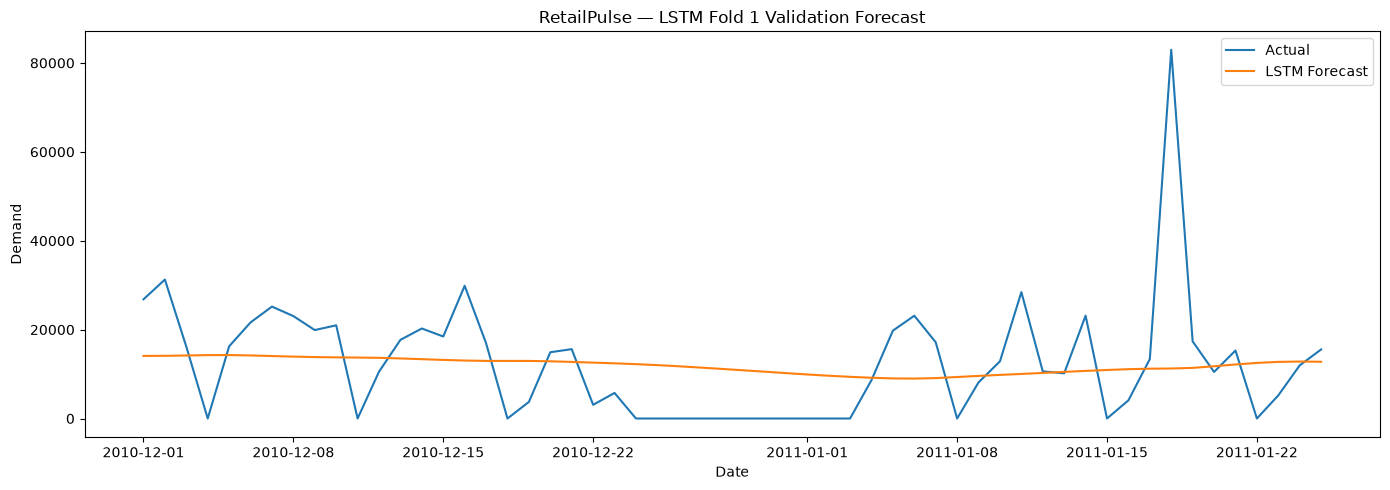

In [53]:
plt.figure(figsize=(14, 5))

plt.plot(
    fold1_predictions["ds"],
    fold1_predictions["actual"],
    label="Actual"
)

plt.plot(
    fold1_predictions["ds"],
    fold1_predictions["predicted"],
    label="LSTM Forecast"
)

plt.title("RetailPulse — LSTM Fold 1 Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
lstm_features = lstm_df_full.copy()

# Make sure dates are datetime
lstm_features["ds"] = pd.to_datetime(lstm_features["ds"])

# -----------------------------
# 1. Log-transform demand
# -----------------------------
lstm_features["log_demand"] = np.log1p(lstm_features["y"])

# -----------------------------
# 2. Day-of-week
# Monday = 0 ... Sunday = 6
# -----------------------------
lstm_features["day_of_week"] = (lstm_features["ds"].dt.dayofweek)

# Weekly cyclic features
lstm_features["dow_sin"] = np.sin(2 * np.pi * lstm_features["day_of_week"] / 7)

lstm_features["dow_cos"] = np.cos(2 * np.pi * lstm_features["day_of_week"] / 7)

# -----------------------------
# 3. Annual seasonality
# -----------------------------
day_of_year = lstm_features["ds"].dt.dayofyear

lstm_features["year_sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
)

lstm_features["year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

lstm_features.head(10)

,ds,y,log_demand,day_of_week,dow_sin,dow_cos,year_sin,year_cos
0,2009-12-01,26098.0,10.169652,1,0.781831,0.623490,-0.497204,0.867634
1,2009-12-02,31804.0,10.367379,2,0.974928,-0.222521,-0.482206,0.876058
2,2009-12-03,49221.0,10.804096,3,0.433884,-0.900969,-0.467065,0.884223
3,2009-12-04,21210.0,9.962275,4,-0.433884,-0.900969,-0.451786,0.892126
4,2009-12-05,5119.0,8.540910,5,-0.974928,-0.222521,-0.436373,0.899766
5,2009-12-06,11533.0,9.353054,6,-0.781831,0.623490,-0.420831,0.907139
6,2009-12-07,17955.0,9.795680,0,0.000000,1.000000,-0.405165,0.914244
7,2009-12-08,23143.0,10.049491,1,0.781831,0.623490,-0.389378,0.921078
8,2009-12-09,17840.0,9.789254,2,0.974928,-0.222521,-0.373477,0.927640
9,2009-12-10,23579.0,10.068154,3,0.433884,-0.900969,-0.357464,0.933927


In [56]:
lstm_features.head(20)

,ds,y,log_demand,day_of_week,dow_sin,dow_cos,year_sin,year_cos
0,2009-12-01,26098.0,10.169652,1,0.781831,0.623490,-0.497204,0.867634
1,2009-12-02,31804.0,10.367379,2,0.974928,-0.222521,-0.482206,0.876058
2,2009-12-03,49221.0,10.804096,3,0.433884,-0.900969,-0.467065,0.884223
3,2009-12-04,21210.0,9.962275,4,-0.433884,-0.900969,-0.451786,0.892126
4,2009-12-05,5119.0,8.540910,5,-0.974928,-0.222521,-0.436373,0.899766
5,2009-12-06,11533.0,9.353054,6,-0.781831,0.623490,-0.420831,0.907139
6,2009-12-07,17955.0,9.795680,0,0.000000,1.000000,-0.405165,0.914244
7,2009-12-08,23143.0,10.049491,1,0.781831,0.623490,-0.389378,0.921078
8,2009-12-09,17840.0,9.789254,2,0.974928,-0.222521,-0.373477,0.927640
9,2009-12-10,23579.0,10.068154,3,0.433884,-0.900969,-0.357464,0.933927


In [57]:
FEATURE_COLUMNS = [
    "log_demand",
    "dow_sin",
    "dow_cos",
    "year_sin",
    "year_cos"
]

TARGET_COLUMN = "log_demand"

print("Features:")
print(FEATURE_COLUMNS)

print("\nTarget:")
print(TARGET_COLUMN)

Features:
['log_demand', 'dow_sin', 'dow_cos', 'year_sin', 'year_cos']

Target:
log_demand


In [58]:
FOLD1_TRAIN_END = "2010-11-30"
FOLD1_VAL_START = "2010-12-01"
FOLD1_VAL_END = "2011-01-25"

In [59]:
fold1_train_v2 = lstm_features[(lstm_features["ds"] >= "2009-12-01") & (lstm_features["ds"] <= FOLD1_TRAIN_END)].copy()

fold1_val_v2 = lstm_features[(lstm_features["ds"] >= FOLD1_VAL_START) &(lstm_features["ds"] <= FOLD1_VAL_END)].copy()

print("Fold 1 training:", fold1_train_v2.shape)
print("Fold 1 validation:", fold1_val_v2.shape)

Fold 1 training: (365, 8)
Fold 1 validation: (56, 8)


In [60]:
def prepare_lstm_v2_fold(
    df,
    train_start,
    train_end,
    validation_start,
    validation_end,
    lookback=30
):
    """
    Prepare a feature-enhanced LSTM CV fold.

    Features:
        - log1p(demand)
        - weekly sine/cosine
        - yearly sine/cosine

    The demand scaler is fitted ONLY on training data.
    """

    # Select train/validation data
    
    train_mask = ((df["ds"] >= pd.Timestamp(train_start)) & (df["ds"] <= pd.Timestamp(train_end)))

    val_mask = ((df["ds"] >= pd.Timestamp(validation_start)) & (df["ds"] <= pd.Timestamp(validation_end)))

    train_df = df.loc[train_mask].copy()
    val_df = df.loc[val_mask].copy()

    
    # Scale ONLY log-demand
    demand_scaler = MinMaxScaler()

    train_log_scaled = demand_scaler.fit_transform(train_df[["log_demand"]])

    # Calendar features are already bounded
    # between approximately -1 and 1.
    train_calendar = train_df[["dow_sin", "dow_cos", "year_sin", "year_cos"]].values

    # Combine features
    train_features = np.column_stack([train_log_scaled,train_calendar])

    
    # Training sequences
    X_train = []
    y_train = []

    for i in range(lookback, len(train_features)):
        X_train.append(train_features[i-lookback:i])

        y_train.append(train_log_scaled[i])

    X_train = np.array(X_train)
    y_train = np.array(y_train)

    
    # Validation
    # Use last LOOKBACK training
    # observations as historical context.
    history_df = train_df.tail(lookback)

    validation_context = pd.concat(
        [
            history_df,
            val_df
        ],
        ignore_index=True
    )

    context_log_scaled = demand_scaler.transform(validation_context[["log_demand"]])

    context_calendar = validation_context[["dow_sin", "dow_cos", "year_sin", "year_cos"]].values

    context_features = np.column_stack([context_log_scaled, context_calendar])

    X_val = []
    y_val = []

    for i in range(
        lookback,
        len(context_features)
    ):
        X_val.append(context_features[i-lookback:i])

        y_val.append(context_log_scaled[i])

    X_val = np.array(X_val)
    y_val = np.array(y_val)

    return (X_train,y_train,X_val,y_val,demand_scaler,train_df,val_df)

In [61]:
(
    X_train_v2,
    y_train_v2,
    X_val_v2,
    y_val_v2,
    scaler_v2,
    fold1_train_v2,
    fold1_val_v2
) = prepare_lstm_v2_fold(
    lstm_features,
    train_start="2009-12-01",
    train_end="2010-11-30",
    validation_start="2010-12-01",
    validation_end="2011-01-25",
    lookback=30
)

print("Training:")
print("X_train:", X_train_v2.shape)
print("y_train:", y_train_v2.shape)

print("\nValidation:")
print("X_val:", X_val_v2.shape)
print("y_val:", y_val_v2.shape)

print("\nScaler:")
print("Min:", scaler_v2.data_min_)
print("Max:", scaler_v2.data_max_)

Training:
X_train: (335, 30, 5)
y_train: (335, 1)

Validation:
X_val: (56, 30, 5)
y_val: (56, 1)

Scaler:
Min: [0.]
Max: [11.73998135]


In [62]:
print("Original demand:")
print(fold1_train_v2["y"].describe())

print("\nLog-transformed demand:")
print(fold1_train_v2["log_demand"].describe())

Original demand:
count       365.000000
mean      15432.128767
std       14091.498555
min           0.000000
25%        8443.000000
50%       13763.000000
75%       20736.000000
max      125489.000000
Name: y, dtype: float64

Log-transformed demand:
count    365.000000
mean       7.939709
std        3.765002
min        0.000000
25%        9.041211
50%        9.529812
75%        9.939675
max       11.739981
Name: log_demand, dtype: float64


In [63]:
print("Original maximum:",fold1_train_v2["y"].max())

print("Log maximum:",fold1_train_v2["log_demand"].max())

Original maximum: 125489.0
Log maximum: 11.739981353104353


In [64]:
def build_lstm_v2(
    lookback=30,
    n_features=5,
    units_1=64,
    units_2=32,
    dropout_rate=0.2
):

    model = Sequential([
        LSTM(units_1, return_sequences=True,input_shape=(lookback, n_features)),

        Dropout(dropout_rate),

        LSTM(units_2,return_sequences=False),

        Dropout(dropout_rate),

        Dense(16, activation="relu"),

        Dense(1)
    ])

    model.compile(optimizer="adam",loss="mse")

    return model

In [65]:
lstm_model_v2 = build_lstm_v2(lookback=30,n_features=5)

lstm_model_v2.summary()

e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
early_stopping_v2 = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [67]:
history_v2 = lstm_model_v2.fit(
    X_train_v2,
    y_train_v2,
    validation_data=(X_val_v2,y_val_v2),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_v2],
    verbose=1,
    shuffle=False
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 34s 442ms/step - loss: 0.5828 - val_loss: 0.3459
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - loss: 0.2081 - val_loss: 0.1396
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 247ms/step - loss: 0.1500 - val_loss: 0.1481
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - loss: 0.1220 - val_loss: 0.1440
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - loss: 0.1056 - val_loss: 0.1438
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - loss: 0.1068 - val_loss: 0.1400
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - loss: 0.1011 - val_loss: 0.1330
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 0.0977 - val_loss: 0.1369
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - loss: 0.0939 - val_loss: 0.1396
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - loss: 0.0952 - val_loss: 0.1385
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - loss: 0.0865 - val_loss: 0.1333
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 1

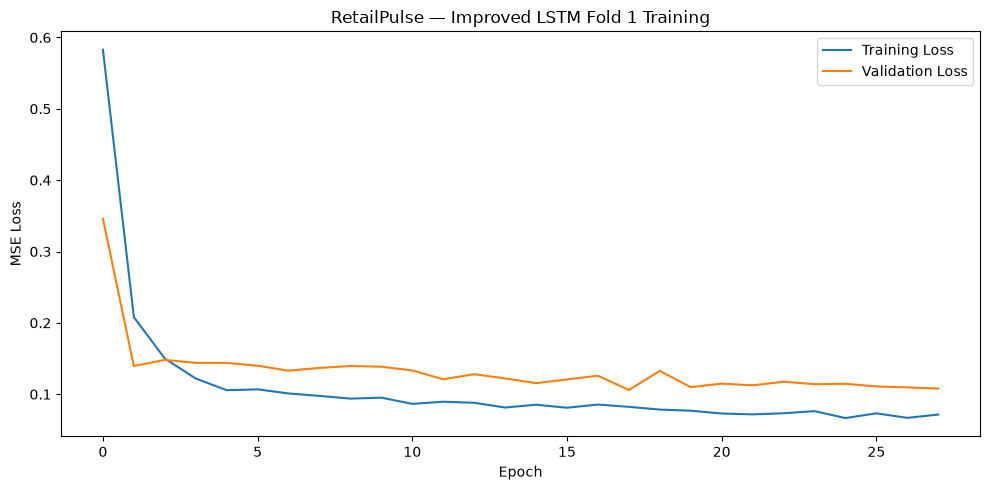

In [69]:
plt.figure(figsize=(10, 5))

plt.plot(history_v2.history["loss"],label="Training Loss")

plt.plot(history_v2.history["val_loss"],label="Validation Loss")

plt.title("RetailPulse — Improved LSTM Fold 1 Training")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [70]:
# Generate predictions in scaled log-demand space
y_val_pred_v2_scaled = lstm_model_v2.predict(X_val_v2,verbose=0)

print("Prediction shape:", y_val_pred_v2_scaled.shape)
print("Actual shape:", y_val_v2.shape)

Prediction shape: (56, 1)
Actual shape: (56, 1)


In [71]:
# Inverse MinMax scaling
y_val_pred_log = scaler_v2.inverse_transform(y_val_pred_v2_scaled)

y_val_actual_log = scaler_v2.inverse_transform(y_val_v2)

# Reverse log1p transformation
y_val_pred_v2 = np.expm1(y_val_pred_log).flatten()

y_val_actual_v2 = np.expm1(y_val_actual_log).flatten()

# Prevent tiny floating-point negatives
y_val_pred_v2 = np.maximum(y_val_pred_v2, 0)

print("First 10 actual values:")
print(y_val_actual_v2[:10])

print("\nFirst 10 predicted values:")
print(y_val_pred_v2[:10])

First 10 actual values:
[26818. 31264. 16158.     0. 16242. 21619. 25180. 23041. 19898. 20973.]

First 10 predicted values:
[25118.533    5837.041     831.9083    309.42142   597.71796  3964.6655
 20065.078   22642.799    5217.4546    734.38434]


In [72]:
# MAe
mae_v2 = mean_absolute_error(y_val_actual_v2,y_val_pred_v2)


# RMSE

rmse_v2 = np.sqrt(mean_squared_error(y_val_actual_v2,y_val_pred_v2))

# MAPE
# Exclude zero actual demand
non_zero_mask = y_val_actual_v2 != 0

mape_v2 = np.mean(
    np.abs((y_val_actual_v2[non_zero_mask]- y_val_pred_v2[non_zero_mask])/y_val_actual_v2[non_zero_mask])) * 100

# WAPE
wape_v2 = (np.sum(np.abs(y_val_actual_v2 - y_val_pred_v2))/np.sum(np.abs(y_val_actual_v2))) * 100


print(f"Fold 1 Improved LSTM MAE:  {mae_v2:.2f}")
print(f"Fold 1 Improved LSTM RMSE: {rmse_v2:.2f}")
print(f"Fold 1 Improved LSTM MAPE: {mape_v2:.2f}%")
print(f"Fold 1 Improved LSTM WAPE: {wape_v2:.2f}%")

Fold 1 Improved LSTM MAE:  9486.31
Fold 1 Improved LSTM RMSE: 15244.12
Fold 1 Improved LSTM MAPE: 82.73%
Fold 1 Improved LSTM WAPE: 76.29%


In [73]:
fold1_predictions_v2 = pd.DataFrame({
    "ds": fold1_val_v2["ds"].values,
    "actual": y_val_actual_v2,
    "predicted": y_val_pred_v2
})

fold1_predictions_v2["residual"] = (fold1_predictions_v2["actual"]- fold1_predictions_v2["predicted"])

print(fold1_predictions_v2.shape)

fold1_predictions_v2.head(10)

(56, 4)


,ds,actual,predicted,residual
0,2010-12-01,26818.0,25118.533203,1699.466797
1,2010-12-02,31264.0,5837.041016,25426.958984
2,2010-12-03,16158.0,831.908325,15326.091675
3,2010-12-04,0.0,309.421417,-309.421417
4,2010-12-05,16242.0,597.717957,15644.282043
5,2010-12-06,21619.0,3964.665527,17654.334473
6,2010-12-07,25180.0,20065.078125,5114.921875
7,2010-12-08,23041.0,22642.798828,398.201172
8,2010-12-09,19898.0,5217.454590,14680.545410
9,2010-12-10,20973.0,734.384338,20238.615662


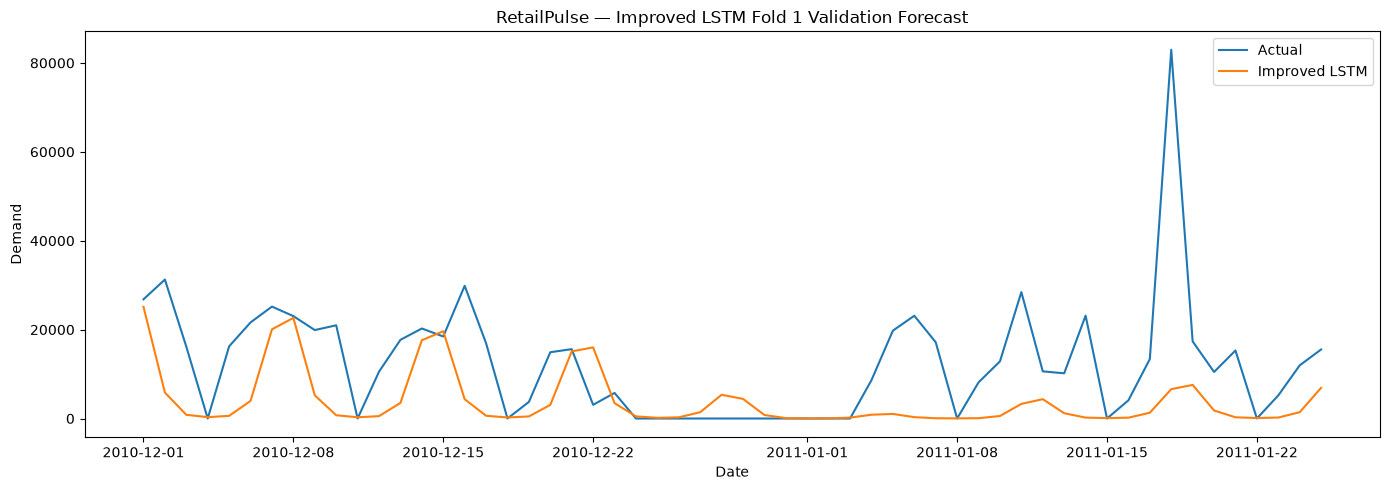

In [74]:
plt.figure(figsize=(14, 5))

plt.plot(
    fold1_predictions_v2["ds"],
    fold1_predictions_v2["actual"],
    label="Actual"
)

plt.plot(
    fold1_predictions_v2["ds"],
    fold1_predictions_v2["predicted"],
    label="Improved LSTM"
)

plt.title("RetailPulse — Improved LSTM Fold 1 Validation Forecast")

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.tight_layout()
plt.show()

In [75]:
comparison_fold1 = pd.DataFrame({
    "Model": [
        "Prophet Smooth",
        "Baseline LSTM",
        "Improved LSTM"
    ],
    "MAE": [
        4201.41,
        9110.04,
        mae_v2
    ],
    "RMSE": [
        6684.06,
        13273.05,
        rmse_v2
    ],
    "MAPE": [
        35.58,
        52.71,
        mape_v2
    ],
    "WAPE": [
        35.73,
        73.27,
        wape_v2
    ]
})

comparison_fold1

,Model,MAE,RMSE,MAPE,WAPE
0,Prophet Smooth,4201.41000,6684.060000,35.580000,35.730000
1,Baseline LSTM,9110.04000,13273.050000,52.710000,73.270000
2,Improved LSTM,9486.31272,15244.116526,82.727532,76.294865


In [76]:
FOLD1_TRAIN_START = "2009-12-01"
FOLD1_TRAIN_END = "2010-11-30"

FOLD1_VAL_START = "2010-12-01"
FOLD1_VAL_END = "2011-01-25"

In [77]:
# Fold 1 training and validation data

fold1_train = lstm_df_full[(lstm_df_full["ds"] >= FOLD1_TRAIN_START) &(lstm_df_full["ds"] <= FOLD1_TRAIN_END)].copy()

fold1_val = lstm_df_full[(lstm_df_full["ds"] >= FOLD1_VAL_START) &(lstm_df_full["ds"] <= FOLD1_VAL_END)].copy()

print("Training shape:", fold1_train.shape)
print("Validation shape:", fold1_val.shape)

print("\nTraining period:")
print(fold1_train["ds"].min(), "→", fold1_train["ds"].max())

print("\nValidation period:")
print(fold1_val["ds"].min(), "→", fold1_val["ds"].max())

Training shape: (365, 2)
Validation shape: (56, 2)

Training period:
2009-12-01 00:00:00 → 2010-11-30 00:00:00

Validation period:
2010-12-01 00:00:00 → 2011-01-25 00:00:00


In [78]:
from prophet import Prophet

Importing plotly failed. Interactive plots will not work.


In [79]:
prophet_fold1 = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

prophet_fold1.fit(fold1_train[["ds", "y"]])

e:\RetailPulse\.venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
11:57:21 - cmdstanpy - INFO - Chain [1] start processing
11:57:30 - cmdstanpy - INFO - Chain [1] done processing


In [80]:
prophet_train_future = fold1_train[["ds"]].copy()

prophet_val_future = fold1_val[["ds"]].copy()

In [81]:
prophet_train_forecast = prophet_fold1.predict(prophet_train_future)

prophet_val_forecast = prophet_fold1.predict(prophet_val_future)

In [82]:
train_prophet_pred = prophet_train_forecast["yhat"].values
val_prophet_pred = prophet_val_forecast["yhat"].values

In [83]:
print("Training predictions:", len(train_prophet_pred))
print("Validation predictions:", len(val_prophet_pred))

Training predictions: 365
Validation predictions: 56


In [84]:
fold1_train["prophet_yhat"] = train_prophet_pred

fold1_train["residual"] = (fold1_train["y"]- fold1_train["prophet_yhat"])

fold1_val["prophet_yhat"] = val_prophet_pred

In [85]:
fold1_train[["ds", "y", "prophet_yhat", "residual"]].head(10)

,ds,y,prophet_yhat,residual
0,2009-12-01,26098.0,29828.991097,-3730.991097
1,2009-12-02,31804.0,28986.459902,2817.540098
2,2009-12-03,49221.0,31261.631771,17959.368229
3,2009-12-04,21210.0,24552.652316,-3342.652316
4,2009-12-05,5119.0,8932.008950,-3813.008950
5,2009-12-06,11533.0,18986.031105,-7453.031105
6,2009-12-07,17955.0,29741.849743,-11786.849743
7,2009-12-08,23143.0,25846.683971,-2703.683971
8,2009-12-09,17840.0,24400.191954,-6560.191954
9,2009-12-10,23579.0,26074.273810,-2495.273810


In [86]:
print(fold1_train["residual"].describe())

count      365.000000
mean        -4.746479
std      10949.960687
min     -22603.739725
25%      -5380.618350
50%      -1037.514619
75%       2927.036917
max      90562.176073
Name: residual, dtype: float64


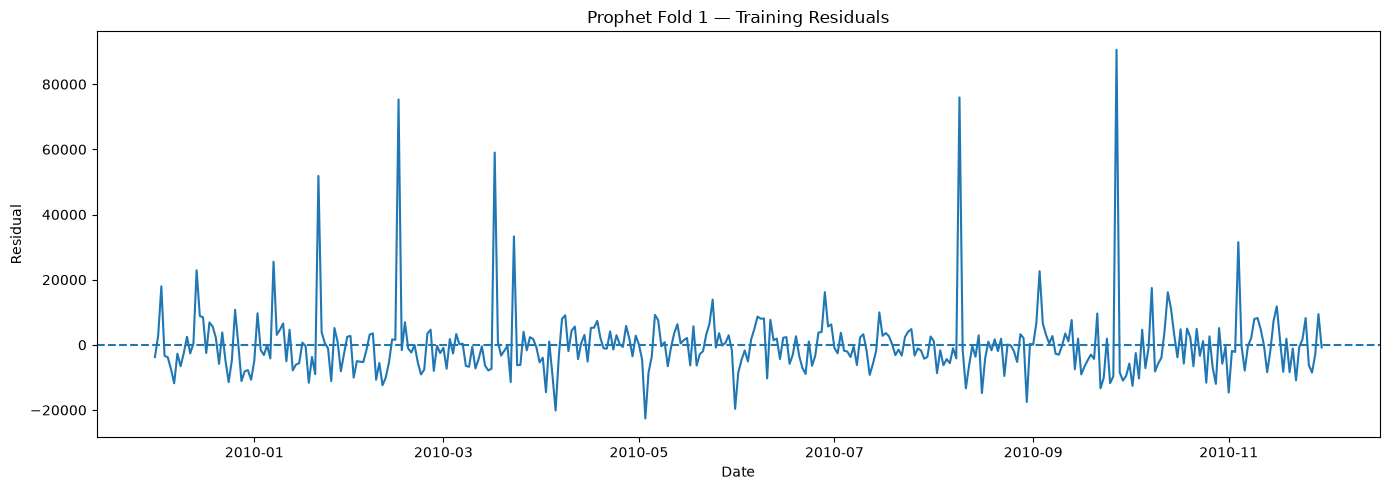

In [87]:
plt.figure(figsize=(14, 5))

plt.plot(fold1_train["ds"],fold1_train["residual"])

plt.axhline(0,linestyle="--")

plt.title("Prophet Fold 1 — Training Residuals")

plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [89]:
from sklearn.preprocessing import StandardScaler

residual_scaler = StandardScaler()

train_residual_scaled = residual_scaler.fit_transform(fold1_train[["residual"]])

print("Scaled residual shape:", train_residual_scaled.shape)

print("Mean:",train_residual_scaled.mean())

print("Std:",train_residual_scaled.std())

Scaled residual shape: (365, 1)
Mean: 1.2166827667125003e-18
Std: 1.0


In [90]:
RESIDUAL_LOOKBACK = 30

X_res_train = []
y_res_train = []

for i in range(
    RESIDUAL_LOOKBACK,
    len(train_residual_scaled)
):

    X_res_train.append(train_residual_scaled[i-RESIDUAL_LOOKBACK:i])

    y_res_train.append(train_residual_scaled[i])

X_res_train = np.array(X_res_train)
y_res_train = np.array(y_res_train)

print("X residual shape:", X_res_train.shape)
print("y residual shape:", y_res_train.shape)

X residual shape: (335, 30, 1)
y residual shape: (335, 1)


In [91]:
def build_residual_lstm(
    lookback=30,
    units_1=32,
    units_2=16,
    dropout_rate=0.2
):

    model = Sequential([LSTM(units_1,return_sequences=True,input_shape=(lookback, 1)),

        Dropout(dropout_rate),

        LSTM(units_2,return_sequences=False),

        Dropout(dropout_rate),

        Dense(8, activation="relu"),

        Dense(1)
    ])

    model.compile(optimizer="adam",loss="mse")

    return model

In [92]:
residual_lstm = build_residual_lstm(lookback=RESIDUAL_LOOKBACK)

residual_lstm.summary()

e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,633 (29.82 KB)

 Trainable params: 7,633 (29.82 KB)

 Non-trainable params: 0 (0.00 B)

In [93]:
residual_early_stopping = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [94]:
RESIDUAL_INTERNAL_VAL = 56

X_res_fit = X_res_train[:-RESIDUAL_INTERNAL_VAL]
y_res_fit = y_res_train[:-RESIDUAL_INTERNAL_VAL]

X_res_internal_val = X_res_train[-RESIDUAL_INTERNAL_VAL:]
y_res_internal_val = y_res_train[-RESIDUAL_INTERNAL_VAL:]

print("Residual LSTM training:")
print(X_res_fit.shape)
print(y_res_fit.shape)

print("\nInternal validation:")
print(X_res_internal_val.shape)
print(y_res_internal_val.shape)

Residual LSTM training:
(279, 30, 1)
(279, 1)

Internal validation:
(56, 30, 1)
(56, 1)


In [95]:
residual_history = residual_lstm.fit(
    X_res_fit,
    y_res_fit,
    validation_data=(X_res_internal_val,y_res_internal_val),
    epochs=100,
    batch_size=32,
    callbacks=[residual_early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 34s 323ms/step - loss: 1.1329 - val_loss: 0.5517
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 1.1257 - val_loss: 0.5474
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 1.1139 - val_loss: 0.5417
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 1.1004 - val_loss: 0.5336
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 1.0814 - val_loss: 0.5210
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - loss: 1.0745 - val_loss: 0.5094
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 1.0511 - val_loss: 0.5117
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 1.0419 - val_loss: 0.5113
Epoch 9/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 1.0347 - val_loss: 0.5140
Epoch 10/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 1.0261 - val_loss: 0.5209
Epoch 11/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.9969 - val_loss: 0.5279
Epoch 12/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.9875 - val_

In [96]:
validation_residual_context = np.concatenate([train_residual_scaled[-RESIDUAL_LOOKBACK:],np.zeros((len(fold1_val), 1))])

In [97]:
def recursive_residual_forecast(
    model,
    last_training_residuals,
    forecast_steps,
    scaler,
    lookback=30
):

    history = list(last_training_residuals.flatten())

    predictions = []

    for _ in range(forecast_steps):

        # Last LOOKBACK residuals
        sequence = np.array(history[-lookback:]).reshape(1,lookback,1)

        # Predict scaled residual
        pred_scaled = model.predict(sequence,verbose=0)[0, 0]

        predictions.append(pred_scaled)

        # Add prediction to history
        history.append(pred_scaled)

    predictions = np.array(predictions).reshape(-1, 1)

    # Convert from standardized residual
    # back to actual residual units
    predictions = scaler.inverse_transform(predictions).flatten()

    return predictions

In [98]:
lstm_residual_predictions = recursive_residual_forecast(
    model=residual_lstm,
    last_training_residuals=train_residual_scaled[-RESIDUAL_LOOKBACK:],
    forecast_steps=len(fold1_val),
    scaler=residual_scaler,
    lookback=RESIDUAL_LOOKBACK
)

print("Residual predictions shape:",lstm_residual_predictions.shape)

print(lstm_residual_predictions[:10])

Residual predictions shape: (56,)
[ -84.33083  -319.37277  -204.78099  -124.462875  841.2747    794.6489
  503.7794    426.02457   400.94858   533.4903  ]


In [99]:
hybrid_prediction = (fold1_val["prophet_yhat"].values+ lstm_residual_predictions)

# Demand cannot be negative
hybrid_prediction = np.maximum(hybrid_prediction,0)

In [100]:
hybrid_actual = fold1_val["y"].values

hybrid_mae = mean_absolute_error(hybrid_actual,hybrid_prediction)

hybrid_rmse = np.sqrt(mean_squared_error(hybrid_actual,hybrid_prediction))

non_zero_mask = hybrid_actual != 0

hybrid_mape = np.mean(np.abs((hybrid_actual[non_zero_mask]- hybrid_prediction[non_zero_mask])/hybrid_actual[non_zero_mask])) * 100

hybrid_wape = (np.sum(np.abs(hybrid_actual- hybrid_prediction))/np.sum(np.abs(hybrid_actual))) * 100

print(f"Fold 1 Hybrid MAE:  {hybrid_mae:.2f}")

print(f"Fold 1 Hybrid RMSE: {hybrid_rmse:.2f}")

print(f"Fold 1 Hybrid MAPE: {hybrid_mape:.2f}%")

print(f"Fold 1 Hybrid WAPE: {hybrid_wape:.2f}%")

Fold 1 Hybrid MAE:  5347.01
Fold 1 Hybrid RMSE: 10622.84
Fold 1 Hybrid MAPE: 36.18%
Fold 1 Hybrid WAPE: 43.00%


In [101]:
fold1_model_comparison = pd.DataFrame({
    "Model": [
        "Prophet Smooth",
        "Baseline LSTM",
        "Improved LSTM",
        "Prophet + LSTM Hybrid"
    ],
    "MAE": [
        4201.41,
        9110.04,
        9486.31,
        hybrid_mae
    ],
    "RMSE": [
        6684.06,
        13273.05,
        15244.12,
        hybrid_rmse
    ],
    "MAPE": [
        35.58,
        52.71,
        82.73,
        hybrid_mape
    ],
    "WAPE": [
        35.73,
        73.27,
        76.29,
        hybrid_wape
    ]
})

fold1_model_comparison

,Model,MAE,RMSE,MAPE,WAPE
0,Prophet Smooth,4201.410000,6684.060000,35.580000,35.730000
1,Baseline LSTM,9110.040000,13273.050000,52.710000,73.270000
2,Improved LSTM,9486.310000,15244.120000,82.730000,76.290000
3,Prophet + LSTM Hybrid,5347.007764,10622.843328,36.183435,43.003983


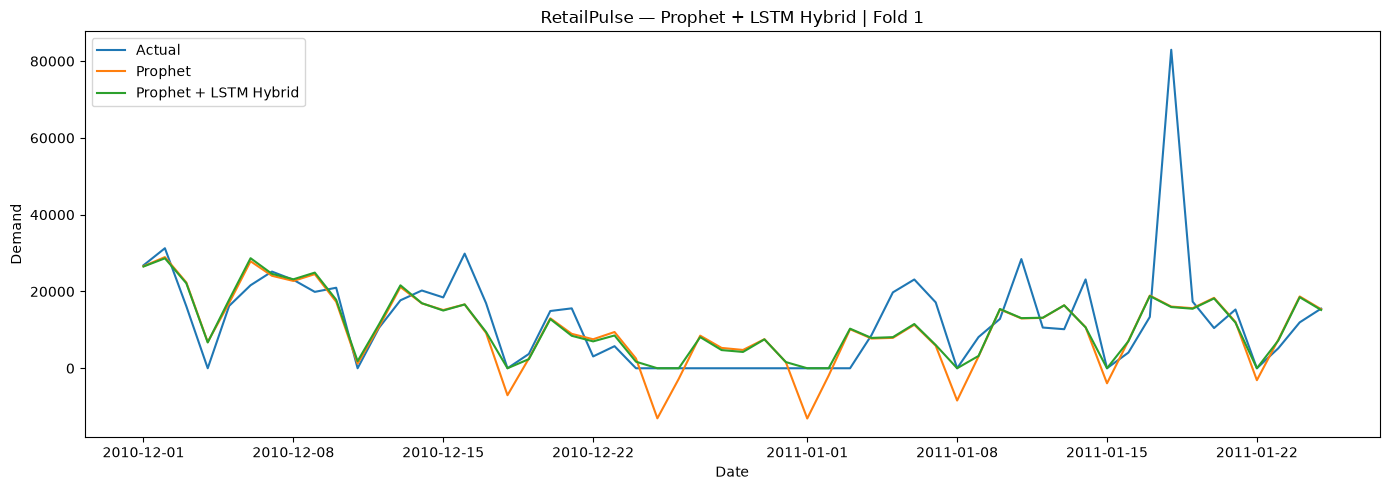

In [102]:
plt.figure(figsize=(14, 5))

plt.plot(fold1_val["ds"],hybrid_actual,label="Actual")

plt.plot(fold1_val["ds"],fold1_val["prophet_yhat"],label="Prophet")

plt.plot(fold1_val["ds"],hybrid_prediction,label="Prophet + LSTM Hybrid")

plt.title("RetailPulse — Prophet + LSTM Hybrid | Fold 1")

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.tight_layout()
plt.show()

In [103]:
def run_prophet_lstm_hybrid_fold(
    df,
    train_start,
    train_end,
    val_start,
    val_end,
    lookback=30,
    internal_val_size=56,
    epochs=100,
    batch_size=32
):
    """
    Run one leakage-safe Prophet + LSTM residual hybrid CV fold.

    Prophet:
        Fits only on the fold's training period.

    Residual LSTM:
        Learns Prophet residuals from the training period only.

    Validation:
        Forecasts residuals recursively without using
        actual validation residuals.
    """

    # 1. TRAIN / VALIDATION SPLIT

    train_df = df[(df["ds"] >= pd.Timestamp(train_start)) & (df["ds"] <= pd.Timestamp(train_end))].copy()

    val_df = df[(df["ds"] >= pd.Timestamp(val_start)) & (df["ds"] <= pd.Timestamp(val_end))].copy()

    train_df = train_df.sort_values("ds").reset_index(drop=True)
    val_df = val_df.sort_values("ds").reset_index(drop=True)

    print("=" * 60)
    print(f"Training:   {train_df['ds'].min().date()} → "
          f"{train_df['ds'].max().date()}")
    print(f"Validation: {val_df['ds'].min().date()} → "
          f"{val_df['ds'].max().date()}")

    print(f"Training shape:   {train_df.shape}")
    print(f"Validation shape: {val_df.shape}")

  
    # 2. PROPHET
    
    prophet_model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="additive"
    )

    prophet_model.fit(train_df[["ds", "y"]])

    # Prophet predictions on training data
    train_forecast = prophet_model.predict(train_df[["ds"]])

    train_df["prophet_yhat"] = (train_forecast["yhat"].values)

    # Prophet predictions on validation data
    val_forecast = prophet_model.predict(val_df[["ds"]])

    val_df["prophet_yhat"] = (val_forecast["yhat"].values)

    # 3. PROPHET TRAINING RESIDUALS

    train_df["residual"] = (train_df["y"]- train_df["prophet_yhat"])

    # 4. SCALE RESIDUALS

    residual_scaler = StandardScaler()

    residual_scaled = residual_scaler.fit_transform(train_df[["residual"]])

    # 5. CREATE RESIDUAL SEQUENCES

    X_residual = []
    y_residual = []

    for i in range(
        lookback,
        len(residual_scaled)
    ):

        X_residual.append(residual_scaled[i-lookback:i])

        y_residual.append(residual_scaled[i])

    X_residual = np.array(X_residual)
    y_residual = np.array(y_residual)

    # 6. INTERNAL VALIDATION

    actual_internal_val_size = min(internal_val_size,len(X_residual) // 4)

    X_res_fit = X_residual[:-actual_internal_val_size]

    y_res_fit = y_residual[:-actual_internal_val_size]

    X_res_internal_val = X_residual[-actual_internal_val_size:]

    y_res_internal_val = y_residual[-actual_internal_val_size:]

    # 7. BUILD RESIDUAL LSTM

    residual_lstm = Sequential([
        LSTM(32,return_sequences=True,input_shape=(lookback, 1)),
        Dropout(0.2),
        LSTM(16,return_sequences=False),
        Dropout(0.2),
        Dense(8,activation="relu"),
        Dense(1)
    ])

    residual_lstm.compile(optimizer="adam",loss="mse")

    residual_early_stopping = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

    # 8. TRAIN RESIDUAL LSTM

    residual_history = residual_lstm.fit(
        X_res_fit,
        y_res_fit,
        validation_data=(X_res_internal_val,y_res_internal_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[residual_early_stopping],
        shuffle=False,
        verbose=0
    )

    print(f"Residual LSTM epochs trained: " f"{len(residual_history.history['loss'])}")

    
    # 9. RECURSIVE RESIDUAL FORECAST


    history = list(residual_scaled[-lookback:].flatten())

    predicted_residual_scaled = []

    for _ in range(len(val_df)):

        sequence = np.array(history[-lookback:]).reshape(1,lookback,1)

        prediction = residual_lstm.predict(sequence,verbose=0)[0, 0]

        predicted_residual_scaled.append(prediction)

        # IMPORTANT:
        # Feed prediction back into history.
        history.append(prediction)

    predicted_residual_scaled = np.array(predicted_residual_scaled).reshape(-1, 1)

    predicted_residual = (residual_scaler.inverse_transform(predicted_residual_scaled).flatten())

    # 10. HYBRID FORECAST

    prophet_prediction = (val_df["prophet_yhat"].values)

    actual = val_df["y"].values

    hybrid_prediction = (prophet_prediction+ predicted_residual)

    # Demand cannot be negative
    hybrid_prediction = np.maximum(hybrid_prediction,0)

    # 11. METRICS

    mae = mean_absolute_error(actual,hybrid_prediction)

    rmse = np.sqrt(mean_squared_error(actual,hybrid_prediction))

    non_zero_mask = actual != 0

    if non_zero_mask.sum() > 0:
        mape = np.mean(np.abs((actual[non_zero_mask]- hybrid_prediction[non_zero_mask])/actual[non_zero_mask])) * 100
    else:
        mape = np.nan

    wape = (np.sum(np.abs(actual- hybrid_prediction))/np.sum(np.abs(actual))) * 100

    # 12. RESULT DATAFRAME

    predictions = pd.DataFrame({
        "ds": val_df["ds"].values,
        "actual": actual,
        "prophet": prophet_prediction,
        "lstm_residual": predicted_residual,
        "hybrid": hybrid_prediction
    })

    metrics = {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "WAPE": wape
    }

    return {
        "model": prophet_model,
        "lstm": residual_lstm,
        "history": residual_history,
        "scaler": residual_scaler,
        "train": train_df,
        "validation": val_df,
        "predictions": predictions,
        "metrics": metrics
    }

In [104]:
hybrid_fold2 = run_prophet_lstm_hybrid_fold(
    df=lstm_df_full,

    train_start="2009-12-01",
    train_end="2011-01-25",

    val_start="2011-01-26",
    val_end="2011-03-22",

    lookback=30,
    internal_val_size=56,
    epochs=100,
    batch_size=32
)

Training:   2009-12-01 → 2011-01-25
Validation: 2011-01-26 → 2011-03-22
Training shape:   (421, 2)
Validation shape: (56, 2)


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
16:24:19 - cmdstanpy - INFO - Chain [1] start processing
16:24:38 - cmdstanpy - INFO - Chain [1] done processing
e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Residual LSTM epochs trained: 15


In [108]:
fold2_metrics = hybrid_fold2["metrics"]

print(f"Fold 2 Hybrid MAE:  "f"{fold2_metrics['MAE']:.2f}")

print(f"Fold 2 Hybrid RMSE: "f"{fold2_metrics['RMSE']:.2f}")

print(f"Fold 2 Hybrid MAPE: "f"{fold2_metrics['MAPE']:.2f}%")

print(f"Fold 2 Hybrid WAPE: "f"{fold2_metrics['WAPE']:.2f}%")

Fold 2 Hybrid MAE:  3891.32
Fold 2 Hybrid RMSE: 4999.71
Fold 2 Hybrid MAPE: 55.29%
Fold 2 Hybrid WAPE: 37.91%


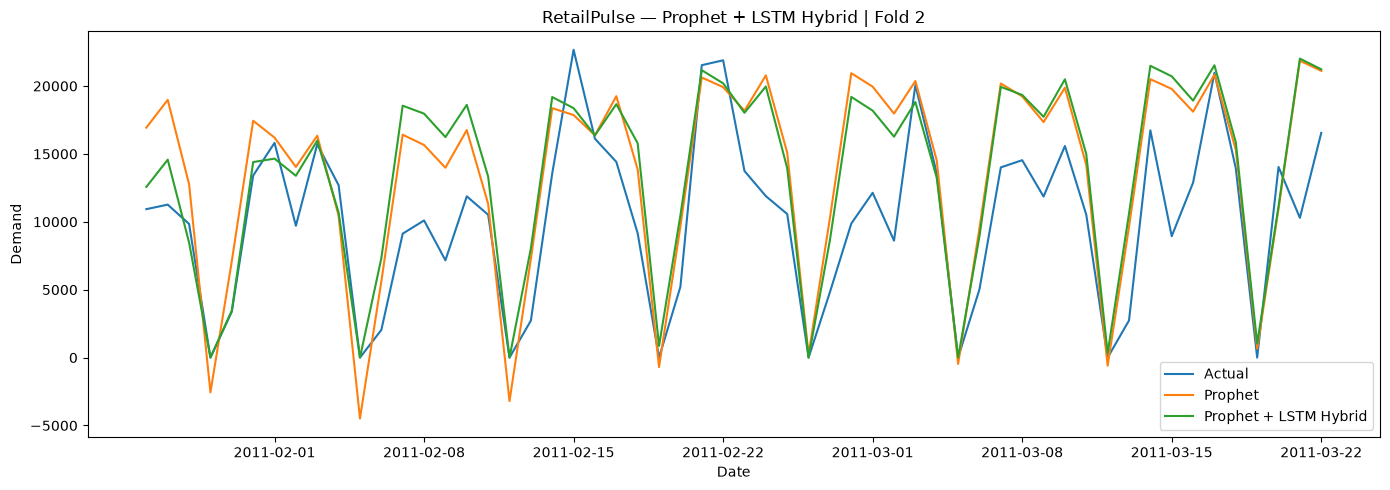

In [106]:
fold2_predictions = hybrid_fold2["predictions"]

plt.figure(figsize=(14, 5))

plt.plot(fold2_predictions["ds"],fold2_predictions["actual"],label="Actual")

plt.plot(fold2_predictions["ds"],fold2_predictions["prophet"],label="Prophet")

plt.plot(fold2_predictions["ds"],fold2_predictions["hybrid"],label="Prophet + LSTM Hybrid")

plt.title("RetailPulse — Prophet + LSTM Hybrid | Fold 2")

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.tight_layout()
plt.show()

In [107]:
fold2_predictions[["ds","actual","prophet","lstm_residual","hybrid"]].head(15)

,ds,actual,prophet,lstm_residual,hybrid
0,2011-01-26,10931.0,16936.266880,-4365.185547,12571.081333
1,2011-01-27,11266.0,18978.627137,-4403.679199,14574.947938
2,2011-01-28,9842.0,12767.158044,-4295.877930,8471.280115
3,2011-01-29,0.0,-2559.206811,-3996.783691,0.000000
4,2011-01-30,3383.0,7106.294043,-3646.659424,3459.634619
5,2011-01-31,13406.0,17441.403291,-3041.891357,14399.511933
6,2011-02-01,15814.0,16201.733281,-1548.901001,14652.832280
7,2011-02-02,9706.0,14044.500905,-654.988647,13389.512258
8,2011-02-03,15712.0,16340.676084,-362.496033,15978.180051
9,2011-02-04,12695.0,10454.917940,218.948883,10673.866823


#fold3

In [109]:
hybrid_fold3 = run_prophet_lstm_hybrid_fold(
    df=lstm_df_full,

    train_start="2009-12-01",
    train_end="2011-03-22",

    val_start="2011-03-23",
    val_end="2011-05-17",

    lookback=30,
    internal_val_size=56,
    epochs=100,
    batch_size=32
)

Training:   2009-12-01 → 2011-03-22
Validation: 2011-03-23 → 2011-05-17
Training shape:   (477, 2)
Validation shape: (56, 2)


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
16:47:24 - cmdstanpy - INFO - Chain [1] start processing
16:47:25 - cmdstanpy - INFO - Chain [1] done processing
e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Residual LSTM epochs trained: 12


In [110]:
fold3_metrics = hybrid_fold3["metrics"]

print(f"Fold 3 Hybrid MAE:  {fold3_metrics['MAE']:.2f}")
print(f"Fold 3 Hybrid RMSE: {fold3_metrics['RMSE']:.2f}")
print(f"Fold 3 Hybrid MAPE: {fold3_metrics['MAPE']:.2f}%")
print(f"Fold 3 Hybrid WAPE: {fold3_metrics['WAPE']:.2f}%")

Fold 3 Hybrid MAE:  4650.34
Fold 3 Hybrid RMSE: 6646.68
Fold 3 Hybrid MAPE: 32.19%
Fold 3 Hybrid WAPE: 38.53%


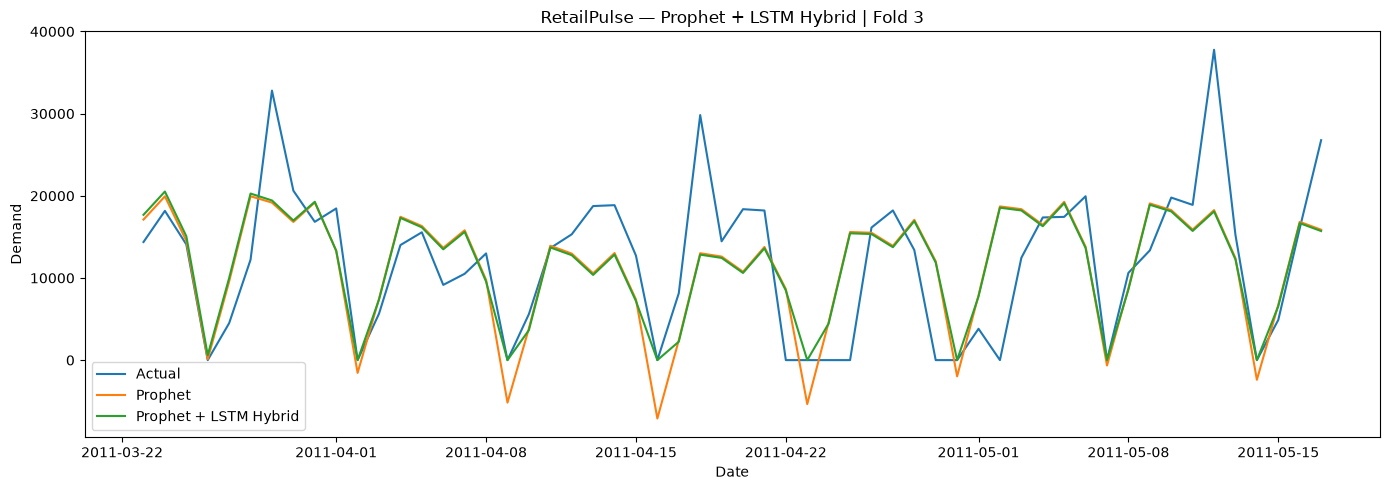

In [111]:
fold3_predictions = hybrid_fold3["predictions"]

plt.figure(figsize=(14, 5))

plt.plot(fold3_predictions["ds"],fold3_predictions["actual"],label="Actual")

plt.plot(fold3_predictions["ds"],fold3_predictions["prophet"],label="Prophet")

plt.plot(fold3_predictions["ds"],fold3_predictions["hybrid"],label="Prophet + LSTM Hybrid")

plt.title("RetailPulse — Prophet + LSTM Hybrid | Fold 3")

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.tight_layout()
plt.show()

In [113]:
hybrid_fold3["predictions"].head(15)

,ds,actual,prophet,lstm_residual,hybrid
0,2011-03-23,14374.0,17105.426225,579.255127,17684.681352
1,2011-03-24,18164.0,19935.418828,583.669434,20519.088262
2,2011-03-25,14083.0,14520.665599,558.594788,15079.260387
3,2011-03-26,0.0,111.657995,495.541321,607.199316
4,2011-03-27,4496.0,9575.859437,409.021851,9984.881288
5,2011-03-28,12222.0,19945.168963,327.938171,20273.107134
6,2011-03-29,32803.0,19173.070213,261.407166,19434.477378
7,2011-03-30,20621.0,16818.308018,176.900970,16995.208988
8,2011-03-31,16832.0,19188.534787,83.051010,19271.585798
9,2011-04-01,18459.0,13309.599283,1.284571,13310.883854


In [114]:
hybrid_fold4 = run_prophet_lstm_hybrid_fold(
    df=lstm_df_full,

    train_start="2009-12-01",
    train_end="2011-05-17",

    val_start="2011-05-18",
    val_end="2011-07-12",

    lookback=30,
    internal_val_size=56,
    epochs=100,
    batch_size=32
)

Training:   2009-12-01 → 2011-05-17
Validation: 2011-05-18 → 2011-07-12
Training shape:   (533, 2)
Validation shape: (56, 2)


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
19:33:36 - cmdstanpy - INFO - Chain [1] start processing
19:33:37 - cmdstanpy - INFO - Chain [1] done processing
e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Residual LSTM epochs trained: 23


In [115]:
fold4_metrics = hybrid_fold4["metrics"]

print(f"Fold 4 Hybrid MAE:  {fold4_metrics['MAE']:.2f}")
print(f"Fold 4 Hybrid RMSE: {fold4_metrics['RMSE']:.2f}")
print(f"Fold 4 Hybrid MAPE: {fold4_metrics['MAPE']:.2f}%")
print(f"Fold 4 Hybrid WAPE: {fold4_metrics['WAPE']:.2f}%")

Fold 4 Hybrid MAE:  3203.39
Fold 4 Hybrid RMSE: 4824.26
Fold 4 Hybrid MAPE: 24.68%
Fold 4 Hybrid WAPE: 26.30%


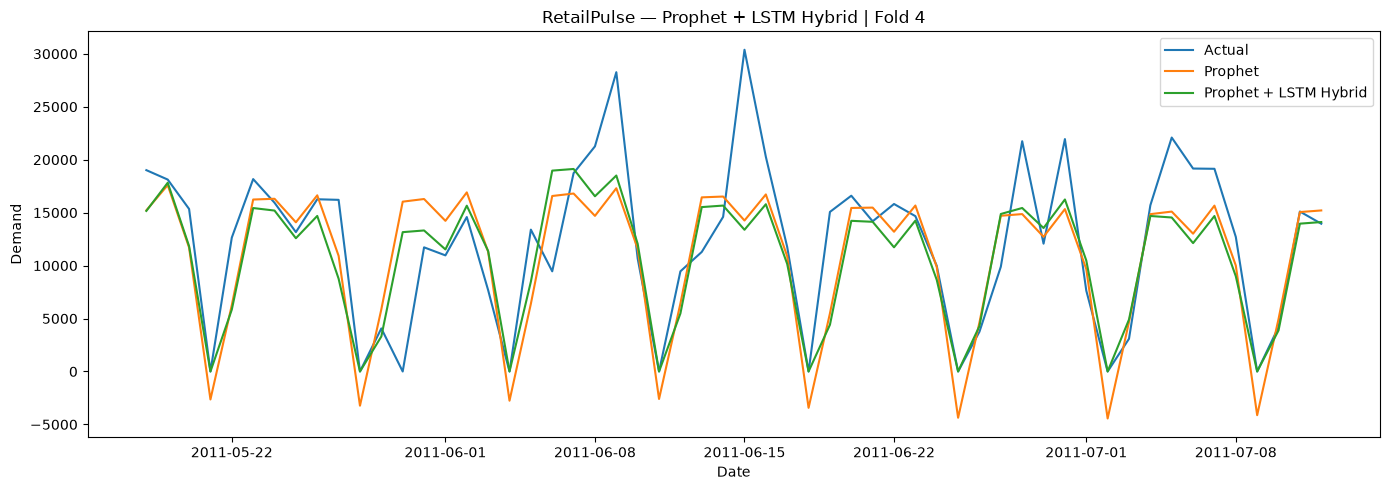

In [116]:
fold4_predictions = hybrid_fold4["predictions"]

plt.figure(figsize=(14, 5))

plt.plot(fold4_predictions["ds"],fold4_predictions["actual"],label="Actual")

plt.plot(fold4_predictions["ds"],fold4_predictions["prophet"],label="Prophet")

plt.plot(fold4_predictions["ds"],fold4_predictions["hybrid"],label="Prophet + LSTM Hybrid")

plt.title("RetailPulse — Prophet + LSTM Hybrid | Fold 4")

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.tight_layout()
plt.show()

In [117]:
fold4_predictions.head(15)

,ds,actual,prophet,lstm_residual,hybrid
0,2011-05-18,19013.0,15219.249574,-55.055618,15164.193956
1,2011-05-19,18124.0,17601.388830,222.693481,17824.082311
2,2011-05-20,15348.0,11702.861007,138.438370,11841.299377
3,2011-05-21,0.0,-2642.077198,-111.591545,0.000000
4,2011-05-22,12645.0,6266.129365,-421.161255,5844.968110
5,2011-05-23,18169.0,16239.356408,-804.932495,15434.423913
6,2011-05-24,15936.0,16310.686805,-1113.412720,15197.274085
7,2011-05-25,13163.0,14087.745941,-1503.289307,12584.456634
8,2011-05-26,16264.0,16636.460538,-1946.275635,14690.184903
9,2011-05-27,16209.0,10921.376706,-2161.536133,8759.840573


In [118]:
print(f"Fold 2 Hybrid MAE:  {fold2_metrics['MAE']:.2f}")

Fold 2 Hybrid MAE:  3891.32


In [119]:
hybrid_cv_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4],

    "MAE": [5347.01,fold2_metrics["MAE"],4650.34,3203.39],

    "RMSE": [10622.84,4999.71,6646.68,4824.26],

    "MAPE": [36.18,55.29,32.19,24.68],

    "WAPE": [43.00,37.91,38.53,26.30]
})

hybrid_cv_results

,Fold,MAE,RMSE,MAPE,WAPE
0,1,5347.010000,10622.84,36.18,43.00
1,2,3891.322367,4999.71,55.29,37.91
2,3,4650.340000,6646.68,32.19,38.53
3,4,3203.390000,4824.26,24.68,26.30


In [120]:
hybrid_cv_summary = pd.DataFrame({
    "Model": ["Prophet + LSTM Hybrid"],

    "MAE_mean": [hybrid_cv_results["MAE"].mean()],

    "MAE_std": [hybrid_cv_results["MAE"].std()],

    "RMSE_mean": [hybrid_cv_results["RMSE"].mean()],

    "RMSE_std": [hybrid_cv_results["RMSE"].std()],

    "MAPE_mean": [hybrid_cv_results["MAPE"].mean()],

    "MAPE_std": [hybrid_cv_results["MAPE"].std()],

    "WAPE_mean": [hybrid_cv_results["WAPE"].mean()],

    "WAPE_std": [hybrid_cv_results["WAPE"].std()]
})

hybrid_cv_summary

,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_std,WAPE_mean,WAPE_std
0,Prophet + LSTM Hybrid,4273.015592,928.372469,6773.3725,2694.3997,37.085,13.039505,36.435,7.126993


In [121]:
final_cv_comparison = pd.DataFrame({
    "Model": ["Prophet Smooth","Prophet + LSTM Hybrid"],

    "MAE_mean": [4814.0318,hybrid_cv_results["MAE"].mean()],

    "RMSE_mean": [6984.2956,hybrid_cv_results["RMSE"].mean()],

    "MAPE_mean": [37.2079,hybrid_cv_results["MAPE"].mean()],

    "WAPE_mean": [40.9576,hybrid_cv_results["WAPE"].mean()]
})

final_cv_comparison

,Model,MAE_mean,RMSE_mean,MAPE_mean,WAPE_mean
0,Prophet Smooth,4814.031800,6984.2956,37.2079,40.9576
1,Prophet + LSTM Hybrid,4273.015592,6773.3725,37.0850,36.4350


In [135]:
print("Development:")
print(train_df["ds"].min(), "→", train_df["ds"].max())

print("\nFinal test:")
print(test_df["ds"].min(), "→", test_df["ds"].max())

print("\nShapes:")
print("Development:", train_df.shape)
print("Final test:", test_df.shape)

Development:
2009-12-01 00:00:00 → 2011-07-14 00:00:00

Final test:
2011-07-15 00:00:00 → 2011-12-09 00:00:00

Shapes:
Development: (591, 2)
Final test: (148, 2)


In [137]:
# FINAL TRAIN / TEST DATA
final_train = train_df.copy()
final_test = test_df.copy()

# Sort chronologically
final_train = final_train.sort_values("ds").reset_index(drop=True)
final_test = final_test.sort_values("ds").reset_index(drop=True)

print("Final training shape:", final_train.shape)
print("Final test shape:", final_test.shape)

print("\nTraining period:")
print(
    final_train["ds"].min(),
    "→",
    final_train["ds"].max()
)

print("\nFinal test period:")
print(
    final_test["ds"].min(),
    "→",
    final_test["ds"].max()
)

Final training shape: (591, 2)
Final test shape: (148, 2)

Training period:
2009-12-01 00:00:00 → 2011-07-14 00:00:00

Final test period:
2011-07-15 00:00:00 → 2011-12-09 00:00:00


In [138]:
final_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

final_prophet.fit(final_train[["ds", "y"]])

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
15:58:00 - cmdstanpy - INFO - Chain [1] start processing
15:58:08 - cmdstanpy - INFO - Chain [1] done processing


In [139]:
final_train_prophet_forecast = final_prophet.predict(final_train[["ds"]])

final_train["prophet_yhat"] = (final_train_prophet_forecast["yhat"].values)

In [140]:
final_test_prophet_forecast = final_prophet.predict(final_test[["ds"]])

final_test["prophet_yhat"] = (final_test_prophet_forecast["yhat"].values)

In [141]:
final_test[["ds", "y", "prophet_yhat"]].head(10)

,ds,y,prophet_yhat
0,2011-07-15,7310.0,10429.374574
1,2011-07-16,0.0,-3589.781999
2,2011-07-17,11019.0,5278.365957
3,2011-07-18,15098.0,14668.507141
4,2011-07-19,29168.0,15161.324151
5,2011-07-20,17676.0,13235.527988
6,2011-07-21,19907.0,15627.581330
7,2011-07-22,10270.0,9677.499453
8,2011-07-23,0.0,-4250.481910
9,2011-07-24,17661.0,4750.653163


In [142]:
final_train["residual"] = (final_train["y"]- final_train["prophet_yhat"])

In [143]:
print(final_train["residual"].describe())

count      591.000000
mean        -3.589904
std       9617.557805
min     -19356.836686
25%      -4357.203739
50%       -962.522181
75%       2629.496360
max      92853.419005
Name: residual, dtype: float64


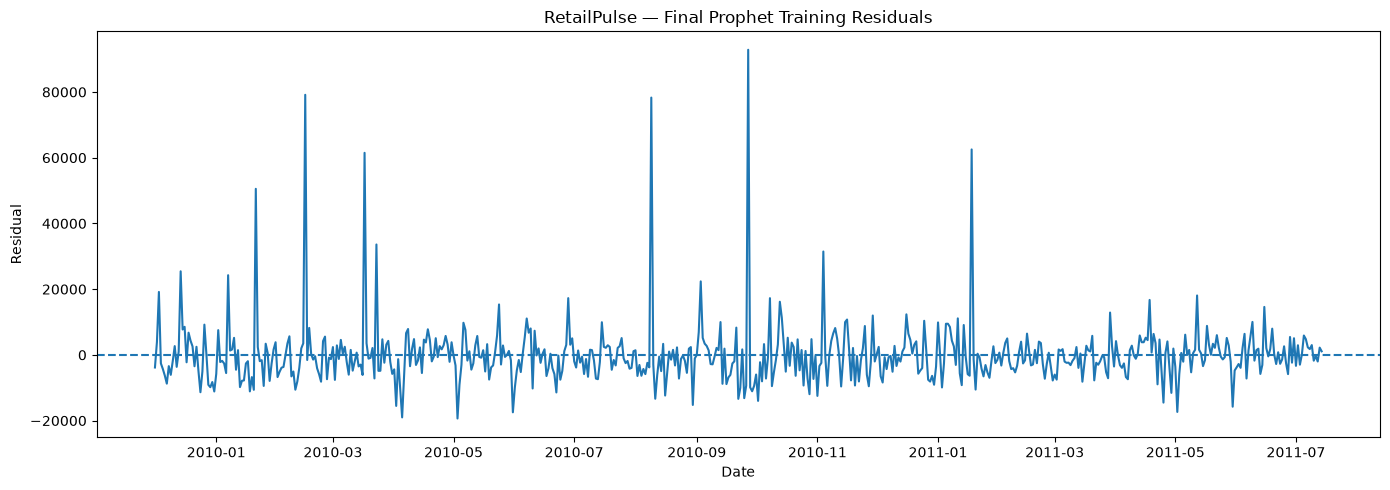

In [144]:
plt.figure(figsize=(14, 5))

plt.plot(final_train["ds"],final_train["residual"])

plt.axhline(0,linestyle="--")

plt.title("RetailPulse — Final Prophet Training Residuals")

plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [145]:
final_residual_scaler = StandardScaler()

final_residual_scaled = (final_residual_scaler.fit_transform(final_train[["residual"]]))

print("Scaled residual shape:",final_residual_scaled.shape)

print("Scaled mean:",final_residual_scaled.mean())

print("Scaled std:",final_residual_scaled.std())

Scaled residual shape: (591, 1)
Scaled mean: 1.80340795878198e-17
Scaled std: 1.0


In [146]:
LOOKBACK = 30

X_final_residual = []
y_final_residual = []

for i in range(
    LOOKBACK,
    len(final_residual_scaled)
):

    X_final_residual.append(final_residual_scaled[i-LOOKBACK:i])

    y_final_residual.append(final_residual_scaled[i])

X_final_residual = np.array(X_final_residual)

y_final_residual = np.array(y_final_residual)

print("X shape:",X_final_residual.shape)

print("y shape:",y_final_residual.shape)

X shape: (561, 30, 1)
y shape: (561, 1)


In [147]:
INTERNAL_VAL_SIZE = 56

X_fit = X_final_residual[:-INTERNAL_VAL_SIZE]

y_fit = y_final_residual[:-INTERNAL_VAL_SIZE]

X_internal_val = X_final_residual[-INTERNAL_VAL_SIZE:]

y_internal_val = y_final_residual[-INTERNAL_VAL_SIZE:]

print("Training:")
print(X_fit.shape, y_fit.shape)

print("\nInternal validation:")
print(
    X_internal_val.shape,
    y_internal_val.shape
)

Training:
(505, 30, 1) (505, 1)

Internal validation:
(56, 30, 1) (56, 1)


In [148]:
final_residual_lstm = Sequential([
    LSTM(32,return_sequences=True,input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(16,return_sequences=False),
    Dropout(0.2),
    Dense(8,activation="relu"),
    Dense(1)
])

final_residual_lstm.compile(optimizer="adam",loss="mse")

final_residual_lstm.summary()

e:\RetailPulse\.venv311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 30, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,633 (29.82 KB)

 Trainable params: 7,633 (29.82 KB)

 Non-trainable params: 0 (0.00 B)

In [149]:
final_early_stopping = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [150]:
final_history = final_residual_lstm.fit(
    X_fit,
    y_fit,

    validation_data=(X_internal_val,y_internal_val),

    epochs=100,
    batch_size=32,

    callbacks=[final_early_stopping],

    shuffle=False,
    verbose=1
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 204ms/step - loss: 1.0915 - val_loss: 0.2449
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - loss: 1.0733 - val_loss: 0.2595
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - loss: 1.0716 - val_loss: 0.2552
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 1.0784 - val_loss: 0.2382
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 1.0514 - val_loss: 0.2686
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 1.0594 - val_loss: 0.2441
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 1.0478 - val_loss: 0.2687
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - loss: 1.0447 - val_loss: 0.2513
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 1.0126 - val_loss: 0.2580
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 1.0190 - val_loss: 0.2911
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.0357 - val_loss: 0.2290
Epoch 12/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/s

In [151]:
best_epoch = (np.argmin(final_history.history["val_loss"]) + 1)

print("Best epoch:",best_epoch)

Best epoch: 11


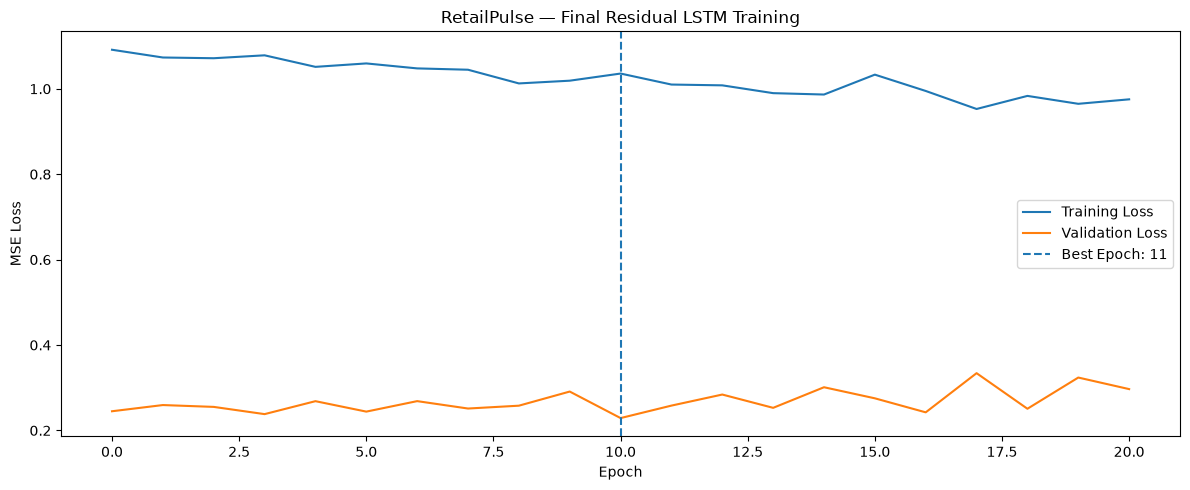

In [152]:
plt.figure(figsize=(12, 5))

plt.plot(final_history.history["loss"],label="Training Loss")

plt.plot(final_history.history["val_loss"],label="Validation Loss")

plt.axvline(best_epoch - 1,linestyle="--",label=f"Best Epoch: {best_epoch}")

plt.title("RetailPulse — Final Residual LSTM Training")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [153]:
final_residual_lstm_full = Sequential([
    LSTM(32,return_sequences=True,input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(16,return_sequences=False),
    Dropout(0.2),
    Dense(8,activation="relu"),
    Dense(1)
])

final_residual_lstm_full.compile(optimizer="adam",loss="mse")

In [154]:
final_residual_history = final_residual_lstm_full.fit(
    X_final_residual,
    y_final_residual,

    epochs=best_epoch,
    batch_size=32,

    shuffle=False,
    verbose=1
)

Epoch 1/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - loss: 1.0115
Epoch 2/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.9956
Epoch 3/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.9965
Epoch 4/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 0.9891
Epoch 5/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.9734
Epoch 6/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.9667
Epoch 7/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.9757
Epoch 8/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.9491
Epoch 9/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.9692
Epoch 10/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.9312
Epoch 11/11
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.9388


In [155]:
history = list(final_residual_scaled[-LOOKBACK:].flatten())

final_residual_predictions_scaled = []

for _ in range(len(final_test)):

    sequence = np.array(history[-LOOKBACK:]).reshape(1,LOOKBACK,1)

    prediction = (final_residual_lstm_full.predict(sequence,verbose=0)[0, 0])

    final_residual_predictions_scaled.append(prediction)

    # Feed prediction back into the sequence
    history.append(prediction)

In [156]:
final_residual_predictions_scaled = np.array(final_residual_predictions_scaled).reshape(-1, 1)

final_residual_predictions = (final_residual_scaler.inverse_transform(final_residual_predictions_scaled).flatten())

print("Residual forecast shape:",final_residual_predictions.shape)

print("First 10 residual predictions:")

print(final_residual_predictions[:10])

Residual forecast shape: (148,)
First 10 residual predictions:
[-2599.417  -2187.1094 -2245.9407 -2384.833  -2454.862  -2375.0256
 -2470.0222 -2077.906  -1539.1577  -764.0734]


In [157]:
final_test["lstm_residual"] = (final_residual_predictions)

final_test["hybrid_prediction"] = (final_test["prophet_yhat"]+ final_test["lstm_residual"])

# Demand cannot be negative
final_test["hybrid_prediction"] = np.maximum(final_test["hybrid_prediction"],0)

In [158]:
final_test[
    [
        "ds",
        "y",
        "prophet_yhat",
        "lstm_residual",
        "hybrid_prediction"
    ]
].head(15)

,ds,y,prophet_yhat,lstm_residual,hybrid_prediction
0,2011-07-15,7310.0,10429.374574,-2599.416992,7829.957581
1,2011-07-16,0.0,-3589.781999,-2187.109375,0.000000
2,2011-07-17,11019.0,5278.365957,-2245.940674,3032.425283
3,2011-07-18,15098.0,14668.507141,-2384.833008,12283.674133
4,2011-07-19,29168.0,15161.324151,-2454.862061,12706.462090
5,2011-07-20,17676.0,13235.527988,-2375.025635,10860.502353
6,2011-07-21,19907.0,15627.581330,-2470.022217,13157.559113
7,2011-07-22,10270.0,9677.499453,-2077.906006,7599.593447
8,2011-07-23,0.0,-4250.481910,-1539.157715,0.000000
9,2011-07-24,17661.0,4750.653163,-764.073425,3986.579738


In [159]:
final_actual = final_test["y"].values
final_prediction = final_test["hybrid_prediction"].values

final_mae = mean_absolute_error(final_actual,final_prediction)

In [160]:
final_rmse = np.sqrt(mean_squared_error(final_actual,final_prediction))

In [161]:
non_zero_mask = final_actual != 0

final_mape = np.mean(np.abs((final_actual[non_zero_mask]- final_prediction[non_zero_mask])/final_actual[non_zero_mask])) * 100

In [162]:
final_wape = (np.sum(np.abs(final_actual- final_prediction))/np.sum(np.abs(final_actual))) * 100

In [163]:
print("=" * 50)
print("RetailPulse — FINAL TEST RESULTS")
print("=" * 50)

print(f"MAE:  {final_mae:.2f}")
print(f"RMSE: {final_rmse:.2f}")
print(f"MAPE: {final_mape:.2f}%")
print(f"WAPE: {final_wape:.2f}%")

RetailPulse — FINAL TEST RESULTS
MAE:  6926.93
RMSE: 10412.09
MAPE: 34.16%
WAPE: 35.23%


In [164]:
prophet_final_prediction = (final_test["prophet_yhat"].values)

prophet_final_mae = mean_absolute_error(final_actual,prophet_final_prediction)

prophet_final_rmse = np.sqrt(mean_squared_error(final_actual,prophet_final_prediction))

prophet_final_mape = np.mean(np.abs((final_actual[non_zero_mask]- prophet_final_prediction[non_zero_mask])/final_actual[non_zero_mask])) * 100

prophet_final_wape = (np.sum(np.abs(final_actual- prophet_final_prediction))/np.sum(np.abs(final_actual))) * 100

In [165]:
final_model_comparison = pd.DataFrame({
    "Model": ["Prophet Smooth","Prophet + LSTM Hybrid"],

    "MAE": [prophet_final_mae,final_mae],

    "RMSE": [prophet_final_rmse,final_rmse],

    "MAPE": [prophet_final_mape,final_mape],

    "WAPE": [prophet_final_wape,final_wape]
})

final_model_comparison

,Model,MAE,RMSE,MAPE,WAPE
0,Prophet Smooth,6988.514946,10307.079521,34.034647,35.546444
1,Prophet + LSTM Hybrid,6926.930736,10412.093871,34.155589,35.233201


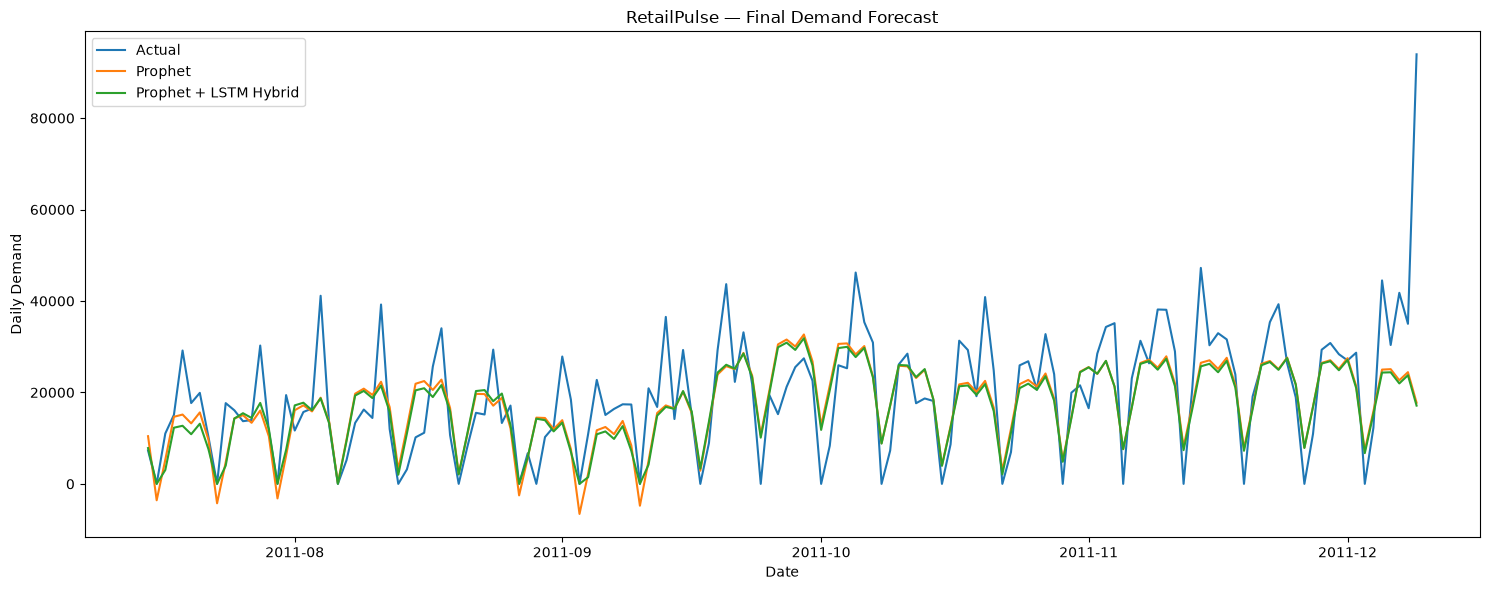

In [166]:
plt.figure(figsize=(15, 6))

plt.plot(final_test["ds"],final_test["y"],label="Actual")

plt.plot(final_test["ds"],final_test["prophet_yhat"],label="Prophet")

plt.plot(final_test["ds"],final_test["hybrid_prediction"],label="Prophet + LSTM Hybrid")

plt.title("RetailPulse — Final Demand Forecast")

plt.xlabel("Date")
plt.ylabel("Daily Demand")

plt.legend()

plt.tight_layout()
plt.show()

In [167]:
final_forecast_df = final_test[
    [
        "ds",
        "y",
        "prophet_yhat",
        "lstm_residual",
        "hybrid_prediction"
    ]
].copy()

final_forecast_df.columns = [
    "date",
    "actual_demand",
    "prophet_forecast",
    "lstm_residual_correction",
    "hybrid_forecast"
]

final_forecast_df.head(10)

,date,actual_demand,prophet_forecast,lstm_residual_correction,hybrid_forecast
0,2011-07-15,7310.0,10429.374574,-2599.416992,7829.957581
1,2011-07-16,0.0,-3589.781999,-2187.109375,0.000000
2,2011-07-17,11019.0,5278.365957,-2245.940674,3032.425283
3,2011-07-18,15098.0,14668.507141,-2384.833008,12283.674133
4,2011-07-19,29168.0,15161.324151,-2454.862061,12706.462090
5,2011-07-20,17676.0,13235.527988,-2375.025635,10860.502353
6,2011-07-21,19907.0,15627.581330,-2470.022217,13157.559113
7,2011-07-22,10270.0,9677.499453,-2077.906006,7599.593447
8,2011-07-23,0.0,-4250.481910,-1539.157715,0.000000
9,2011-07-24,17661.0,4750.653163,-764.073425,3986.579738


In [168]:
print("Final forecast shape:", final_forecast_df.shape)

Final forecast shape: (148, 5)


#FINAL ERROR ANALYSIS

In [170]:
final_forecast_df["absolute_error"] = (final_forecast_df["actual_demand"]- final_forecast_df["hybrid_forecast"]).abs()

largest_errors = (final_forecast_df.sort_values("absolute_error",ascending=False).head(15))

largest_errors

,date,actual_demand,prophet_forecast,lstm_residual_correction,hybrid_forecast,absolute_error
147,2011-12-09,93950.0,17751.728148,-635.610352,17116.117796,76833.882204
20,2011-08-04,41143.0,18848.187878,-141.485718,18706.702160,22436.297840
122,2011-11-14,47236.0,26477.682027,-777.086182,25700.595845,21535.404155
143,2011-12-05,44497.0,24992.981702,-652.729919,24340.251783,20156.748217
145,2011-12-07,41789.0,22655.889608,-687.115173,21968.774434,19820.225566
60,2011-09-13,36519.0,17159.526551,-322.035950,16837.490601,19681.509399
97,2011-10-20,40855.0,22527.092199,-702.582275,21824.509923,19030.490077
82,2011-10-05,46222.0,28319.481146,-584.820679,27734.660467,18487.339533
27,2011-08-11,39228.0,22335.661944,-856.658386,21479.003558,17748.996442
67,2011-09-20,43683.0,25751.591341,298.608490,26050.199831,17632.800169


In [171]:
final_forecast_df["residual"] = (final_forecast_df["actual_demand"]- final_forecast_df["hybrid_forecast"])

In [172]:
print(final_forecast_df["residual"].describe())

count      148.000000
mean      2676.031449
std      10096.501065
min     -14627.317658
25%      -3756.877580
50%         93.118935
75%       7596.343564
max      76833.882204
Name: residual, dtype: float64


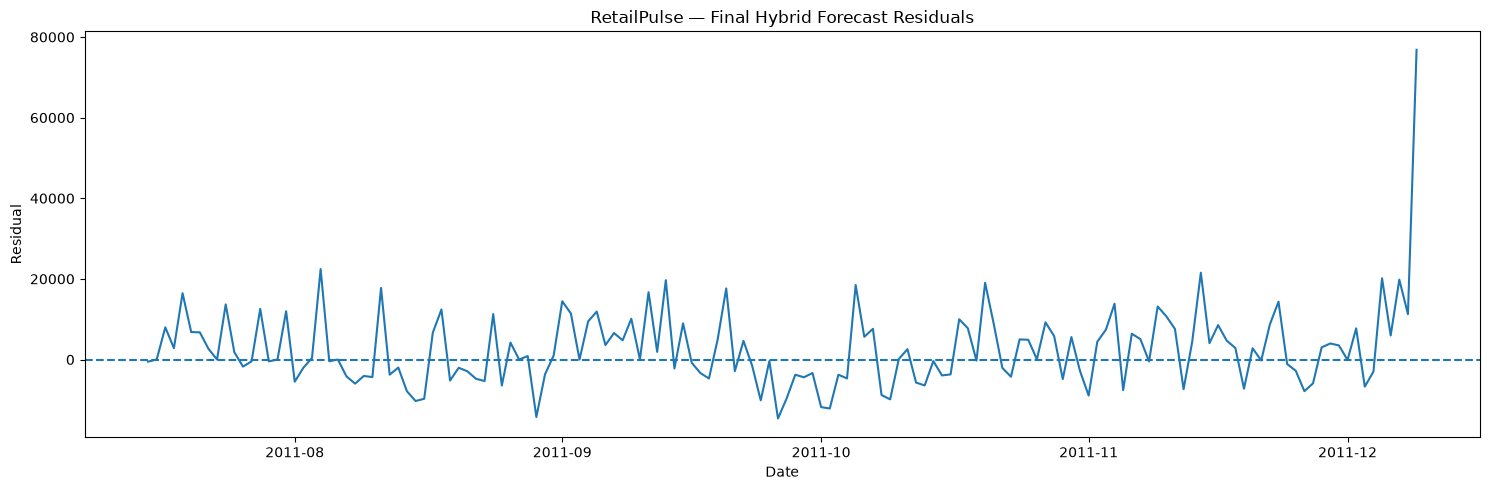

In [173]:
plt.figure(figsize=(15, 5))

plt.plot(final_forecast_df["date"],final_forecast_df["residual"])

plt.axhline(0,linestyle="--")

plt.title("RetailPulse — Final Hybrid Forecast Residuals")

plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [ ]:
final_forecast_df["day_of_week"] = (final_forecast_df["date"].dt.day_name())

weekday_error = (
    final_forecast_df.groupby("day_of_week")
    .agg(actual_mean=("actual_demand", "mean"),forecast_mean=("hybrid_forecast", "mean"),MAE=("absolute_error","mean"))
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekday_error

,actual_mean,forecast_mean,MAE
day_of_week,,,
Monday,22614.523810,21379.804900,7163.330441
Tuesday,24171.190476,22030.929672,6938.732795
Wednesday,24814.523810,20273.046075,6412.869429
Thursday,30146.476190,22804.757835,9103.921042
Friday,22924.681818,16541.151123,8123.112984
Saturday,0.000000,4081.460168,4081.460168
Sunday,12794.809524,11799.383295,6608.127233


In [175]:
final_forecast_df.to_csv("final_demand_forecast.csv",index=False)

print("Saved: final_demand_forecast.csv")

Saved: final_demand_forecast.csv


In [176]:
final_model_comparison.to_csv("final_model_comparison.csv",index=False)

print("Saved: final_model_comparison.csv")

Saved: final_model_comparison.csv


In [177]:
final_metrics = {
    "selected_model": "Prophet + LSTM Hybrid",

    "test_start": str(final_test["ds"].min().date()),

    "test_end": str(final_test["ds"].max().date()),

    "MAE": float(final_mae),

    "RMSE": float(final_rmse),

    "MAPE": float(final_mape),

    "WAPE": float(final_wape),

    "prophet_MAE": float(prophet_final_mae),

    "prophet_RMSE": float(prophet_final_rmse),

    "prophet_MAPE": float(prophet_final_mape),

    "prophet_WAPE": float(prophet_final_wape)
}

final_metrics

{'selected_model': 'Prophet + LSTM Hybrid',
 'test_start': '2011-07-15',
 'test_end': '2011-12-09',
 'MAE': 6926.9307360390885,
 'RMSE': 10412.093871365816,
 'MAPE': 34.15558882628739,
 'WAPE': 35.233201496840245,
 'prophet_MAE': 6988.514946251998,
 'prophet_RMSE': 10307.07952114927,
 'prophet_MAPE': 34.03464681873326,
 'prophet_WAPE': 35.546443965999956}

In [178]:
import json

with open("final_forecasting_metrics.json","w") as f:
    json.dump(final_metrics,f,indent=4)

print("Saved: final_forecasting_metrics.json")

Saved: final_forecasting_metrics.json


In [179]:
final_residual_lstm_full.save("retailpulse_lstm_residual.keras")

print("Saved: retailpulse_lstm_residual.keras")

Saved: retailpulse_lstm_residual.keras


In [180]:
import joblib

joblib.dump(final_residual_scaler,"retailpulse_residual_scaler.pkl")

print("Saved: retailpulse_residual_scaler.pkl")

Saved: retailpulse_residual_scaler.pkl


In [181]:
joblib.dump(final_prophet,"retailpulse_prophet_model.pkl")

print("Saved: retailpulse_prophet_model.pkl")

Saved: retailpulse_prophet_model.pkl


In [183]:
final_model_comparison.to_csv("cross_validation_model_comparison.csv",index=False)

print("Saved: cross_validation_model_comparison.csv")

Saved: cross_validation_model_comparison.csv
